# 客户行为分析：RFM、K-means 分群、队列留存与概率型 CLV

**数据**：UCI Online Retail（英国在线礼品批发商，2010-12-01 至 2011-12-09，541,909 行交易明细）
**问题**：谁是高价值客户？他们多久复购一次？哪些人正在流失？未来半年的收入会从哪里来？

本 notebook 是叙述层：所有计算都在 `src/rfm/` 中实现并有单元测试（`tests/`），这里只负责调用、展示和解读。
同一套逻辑也有 SQL（DuckDB）版本，见 `sql/`，并在第 3 节与 pandas 结果逐行比对。

**阅读顺序**：数据审计 → RFM 特征 → 时间维度（月度、队列、复购周期）→ 分群 → 行为交集 → CLV 与验证 → 结论与局限。

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from rfm.pipeline import run_analysis, write_outputs
from rfm.data import CLEANING_STEPS
from rfm.viz import charts
from rfm.viz.theme import save

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 30)

def show(fig, name):
    """Save the figure to reports/figures and display the saved PNG (what README shows)."""
    display(Image(filename=str(save(fig, name)), width=1100))

## 1. 运行完整分析

`run_analysis()` 完成：读取 → 清洗 → RFM → SQL 一致性校验 → K-means 选 k 与稳定性 → 规则型 RFM 对照 → 代理决策树 →
复购间隔 → 队列 → BG/NBD 留出期验证 → 全量 BG/NBD + Gamma-Gamma CLV。约 25 秒。

In [2]:
res = run_analysis()
write_outputs(res)
m = res.metrics
print(f"原始行数 {m['raw_rows']:,} → 分析行数 {m['clean_rows']:,};  客户 {m['customers']:,}")
print(f"净收入 £{m['net_revenue']:,.0f}  (毛收入 £{m['gross_revenue']:,.0f}, 退货占 {m['return_rate_value']:.1%})")

原始行数 541,909 → 分析行数 399,656;  客户 4,334
净收入 £8,269,400  (毛收入 £8,737,228, 退货占 5.4%)


## 2. 数据审计：先找出会改变结论的问题

清洗规则是有名字、有顺序、可测试的步骤（`rfm.data.CLEANING_STEPS`），同一份规则同时生成干净数据和下面的审计表。

| 规则 | 理由 |
|---|---|
| 去掉完全重复行 | 5,268 行完全相同，属于导出重复 |
| 去掉无 CustomerID 的行 | 游客结账无法归属到客户；它们占 **约 15% 的收入**，所以本分析只描述"注册客户"，不是全部生意 |
| 去掉 UnitPrice ≤ 0 | 赠品/坏账调整，不是消费 |
| 去掉非商品代码 | POST/DOT（邮费）、AMAZONFEE、M（手工调整）、D（折扣）、BANK CHARGES、CRUK、gift voucher 等，不是客户"买商品"的金额 |
| **保留退货（C 开头发票）** | 以负收入保留，Monetary = 购买 − 退货（净额），而不是直接丢掉退货 |

In [3]:
res.audit

,step,rows,revenue,rows_removed,revenue_change
0,Raw extract,541909,"9,747,747.93",0,0.00
1,Exact duplicate lines,536641,"9,726,006.95",5268,"-21,740.98"
2,No CustomerID (guest checkout),401604,"8,278,519.42",135037,"-1,447,487.53"
3,UnitPrice <= 0 (free / write-off),401564,"8,278,519.42",40,0.00
4,"Non-merchandise codes (postage, fees, adjustme...",399656,"8,265,476.93",1908,"-13,042.49"


### 2.1 参考教程的 Monetary 是错的（可复现）

参考教程写了：

```python
df_f = df
df_f.drop_duplicates(subset=['InvoiceNo', 'CustomerID'], keep='first', inplace=True)
```

`df_f` 只是 `df` 的别名，`inplace=True` 让**原表也被去重成每张发票只剩第一行**，随后 `Sales` 只在这些"第一行"上求和。
`replicate_tutorial_rfm()` 原样复现了这段逻辑，得到的均值与教程打印的 `296.76` 完全一致——这证明复现是对的，也证明 bug 是真的。

In [4]:
tut = res.tutorial
print(f"教程 Monetary 均值: £{m['tutorial_mean_monetary']:.2f}   (教程原文: 296.7611131597142)")
print(f"修正后净 Monetary 均值: £{m['corrected_mean_monetary']:,.2f}")
print(f"教程只捕获了 {m['tutorial_revenue_captured']:.1%} 的真实收入")
print()
print("客户 12346：一笔 74,215 件的订单 16 分钟后全部退掉")
display(res.raw[res.raw.CustomerID == '12346'][['InvoiceNo', 'Quantity', 'UnitPrice', 'InvoiceDate']])
print("教程把他算成 Sales = £%.0f 的头部客户；净额实际为 £%.0f。" % (tut.loc['12346', 'Sales'], res.customers.loc['12346', 'monetary']))

教程 Monetary 均值: £296.76   (教程原文: 296.7611131597142)
修正后净 Monetary 均值: £1,908.03
教程只捕获了 14.7% 的真实收入

客户 12346：一笔 74,215 件的订单 16 分钟后全部退掉


,InvoiceNo,Quantity,UnitPrice,InvoiceDate
61619,541431,74215,1.04,2011-01-18 10:01:00
61624,C541433,-74215,1.04,2011-01-18 10:17:00


教程把他算成 Sales = £77184 的头部客户；净额实际为 £0。


教程中的其他问题：

1. **Recency 参考日期**用的是 2012-01-01，比数据最后一天晚 23 天；由于按整天取整，多数客户的 Recency 被多算 21 天；这里用最后发票日的次日（2011-12-10）。
2. **8 类规则分群用均值作阈值**：在偏度 > 20 的分布上，均值被少数大客户拉高，绝大多数客户落在"低"一侧。
3. **K-means 直接跑在原始尺度上**：Monetary 的数量级比 Frequency 大三个数量级，欧氏距离几乎只由 Monetary 决定；而且 `k=8` 的模型拟合后没有被使用。
4. 没有选 k 的依据、没有稳定性检验、也没有把聚类结果翻译成业务规则。

下面每一项都给出了修正。

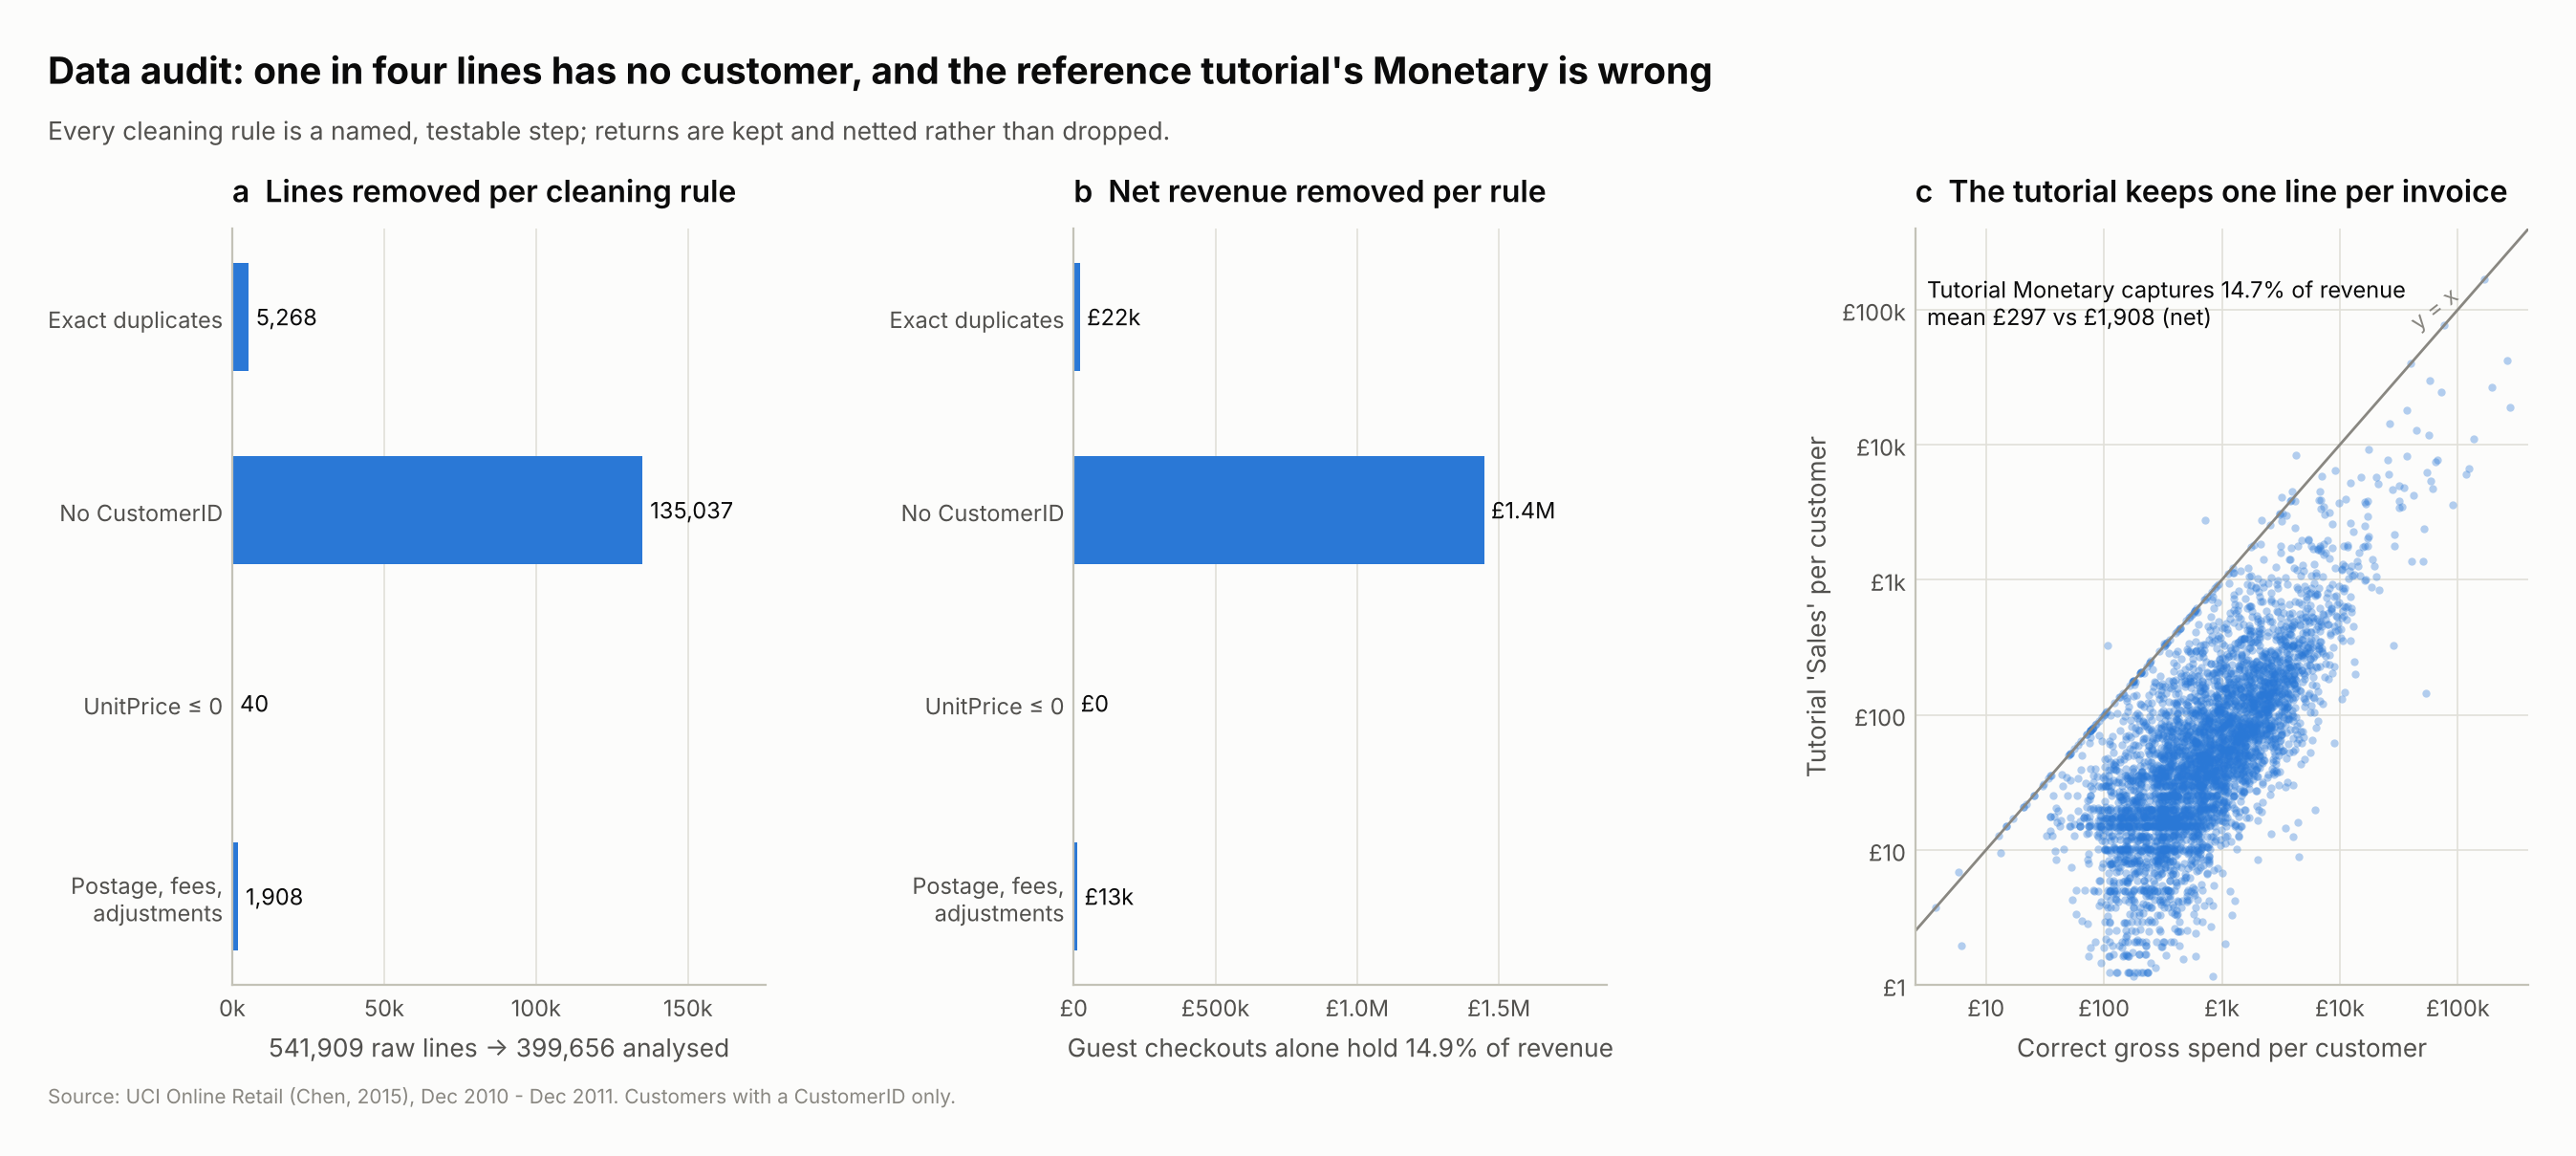

In [5]:
show(charts.fig_data_audit(res.audit, res.tutorial, res.customers, m), "01_data_audit")

## 3. SQL 层与 pandas 一致

`sql/01_clean_transactions.sql`、`sql/02_customer_rfm.sql`、`sql/03_cohort_retention.sql` 是同一逻辑的仓库式（warehouse-style）实现。
在**全量数据**上，SQL 与 pandas 的 RFM 最大绝对差为：

In [6]:
print(f"max |SQL - pandas| over R, F, M = {m['sql_pandas_max_abs_diff']:.2e}  (浮点求和顺序误差)")
from rfm.sql import query_rfm
query_rfm(res.raw).head()

max |SQL - pandas| over R, F, M = 2.91e-10  (浮点求和顺序误差)


,recency_days,frequency,monetary,gross_revenue,returned_value,tenure_days
CustomerID,,,,,,
12346,326,1,0.00,"77,183.60","77,183.60",326
12347,3,7,"4,310.00","4,310.00",0.00,368
12348,76,4,"1,437.24","1,437.24",0.00,359
12349,19,1,"1,457.55","1,457.55",0.00,19
12350,311,1,294.40,294.40,0.00,311


## 4. RFM 特征与收入集中度

- **R** = 距快照日的天数（最后一次购买日）
- **F** = 不同的购买发票数（退货发票不计）
- **M** = 净收入（购买 − 退货）

额外保留了 AOV、在网时长、退货率、国家等，用于解读分群。

In [7]:
cols = ['recency_days', 'frequency', 'monetary', 'aov', 'tenure_days', 'return_rate']
res.customers[cols].describe(percentiles=[.25, .5, .75, .9, .99]).T

,count,mean,std,min,25%,50%,75%,90%,99%,max
recency_days,"4,334.00",93.23,100.18,1.00,18.00,51.00,143.00,264.00,369.00,374.00
frequency,"4,334.00",4.25,7.63,1.00,1.00,2.00,5.00,9.00,30.00,206.00
monetary,"4,334.00","1,908.03","8,291.08",-141.48,296.78,646.84,"1,600.84","3,449.39","17,049.10","278,778.02"
aov,"4,334.00",415.48,"1,800.90",3.75,177.20,289.56,423.41,657.79,"2,023.78","84,236.25"
tenure_days,"4,334.00",223.83,117.84,1.00,113.00,249.00,327.00,367.00,374.00,374.00
return_rate,"4,334.00",0.02,0.09,0.00,0.00,0.00,0.01,0.04,0.39,2.37


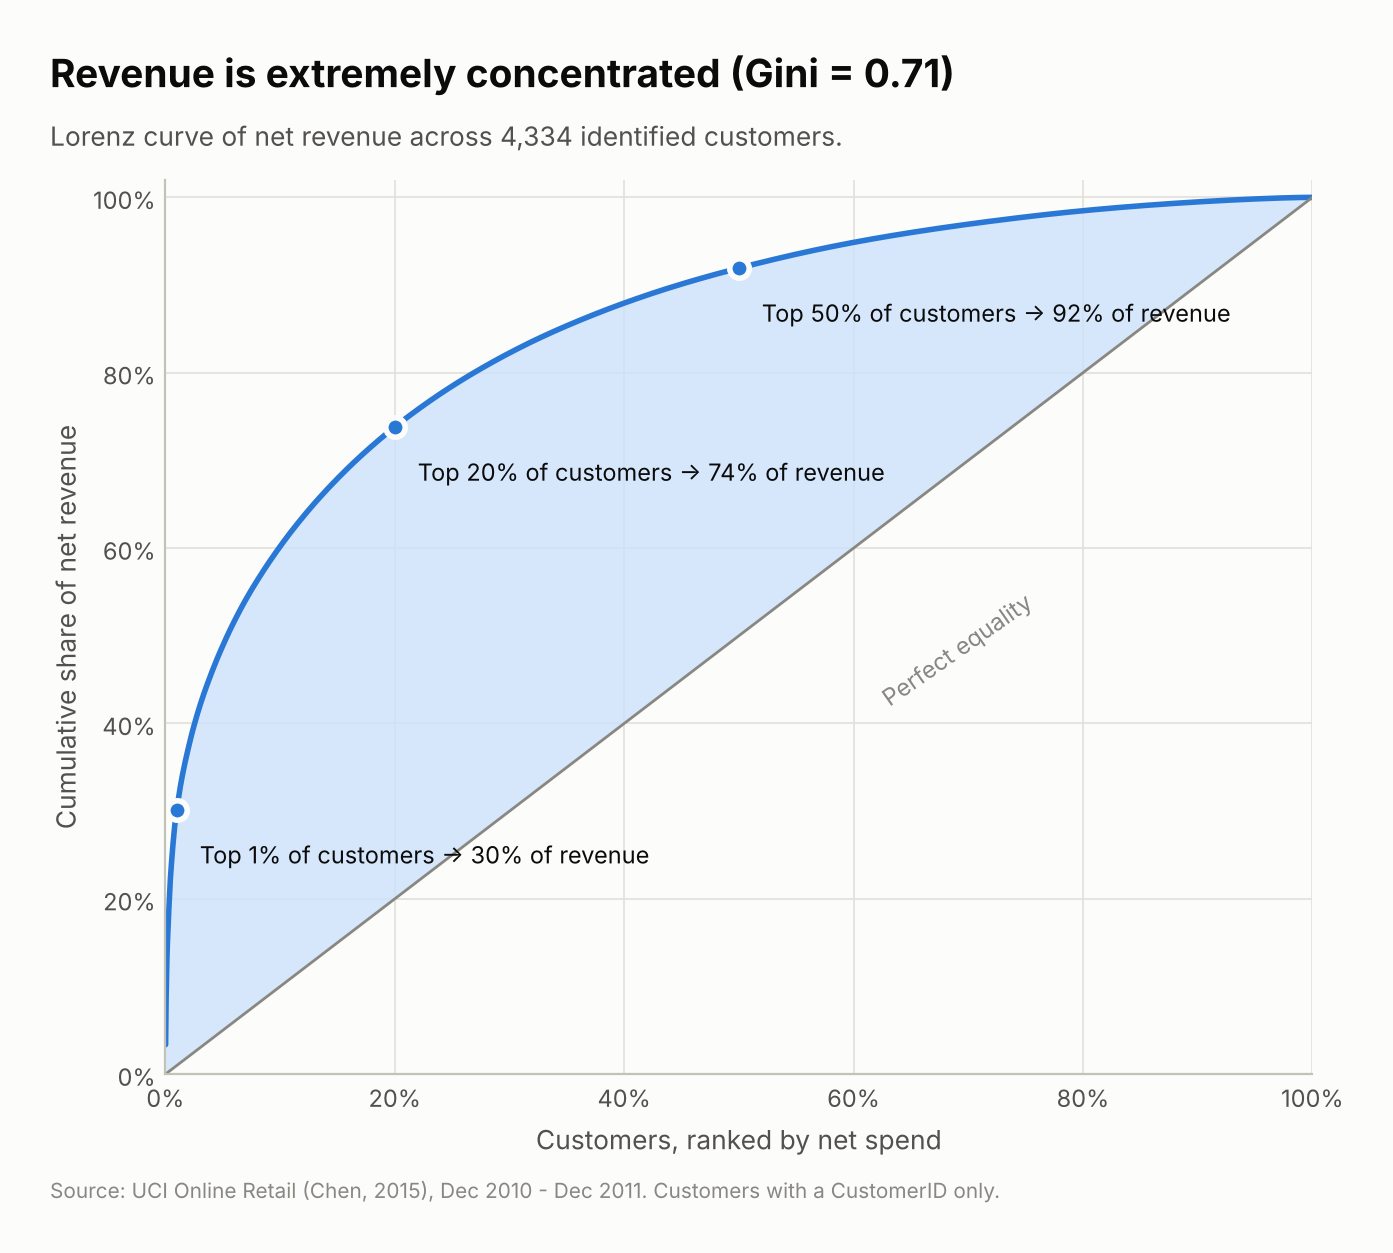

Gini = 0.71;  前 1% 客户贡献 30%,  前 20% 贡献 74%;  一次性购买客户占 35%


In [8]:
fig, gini = charts.fig_revenue_concentration(res.customers, m)
show(fig, "02_revenue_concentration")
print(f"Gini = {gini:.2f};  前 1% 客户贡献 {m['top1_revenue_share']:.0%},  前 20% 贡献 {m['top20_revenue_share']:.0%};  一次性购买客户占 {m['one_time_buyer_share']:.0%}")

**解读**：收入高度集中（帕累托 74/20），并且 35% 的客户只买过一次。这决定了后面两件事：
特征必须取对数再聚类；"平均客户"这个概念在这里没有意义，所有汇总都用中位数。

## 5. 时间维度：月度活跃与队列留存

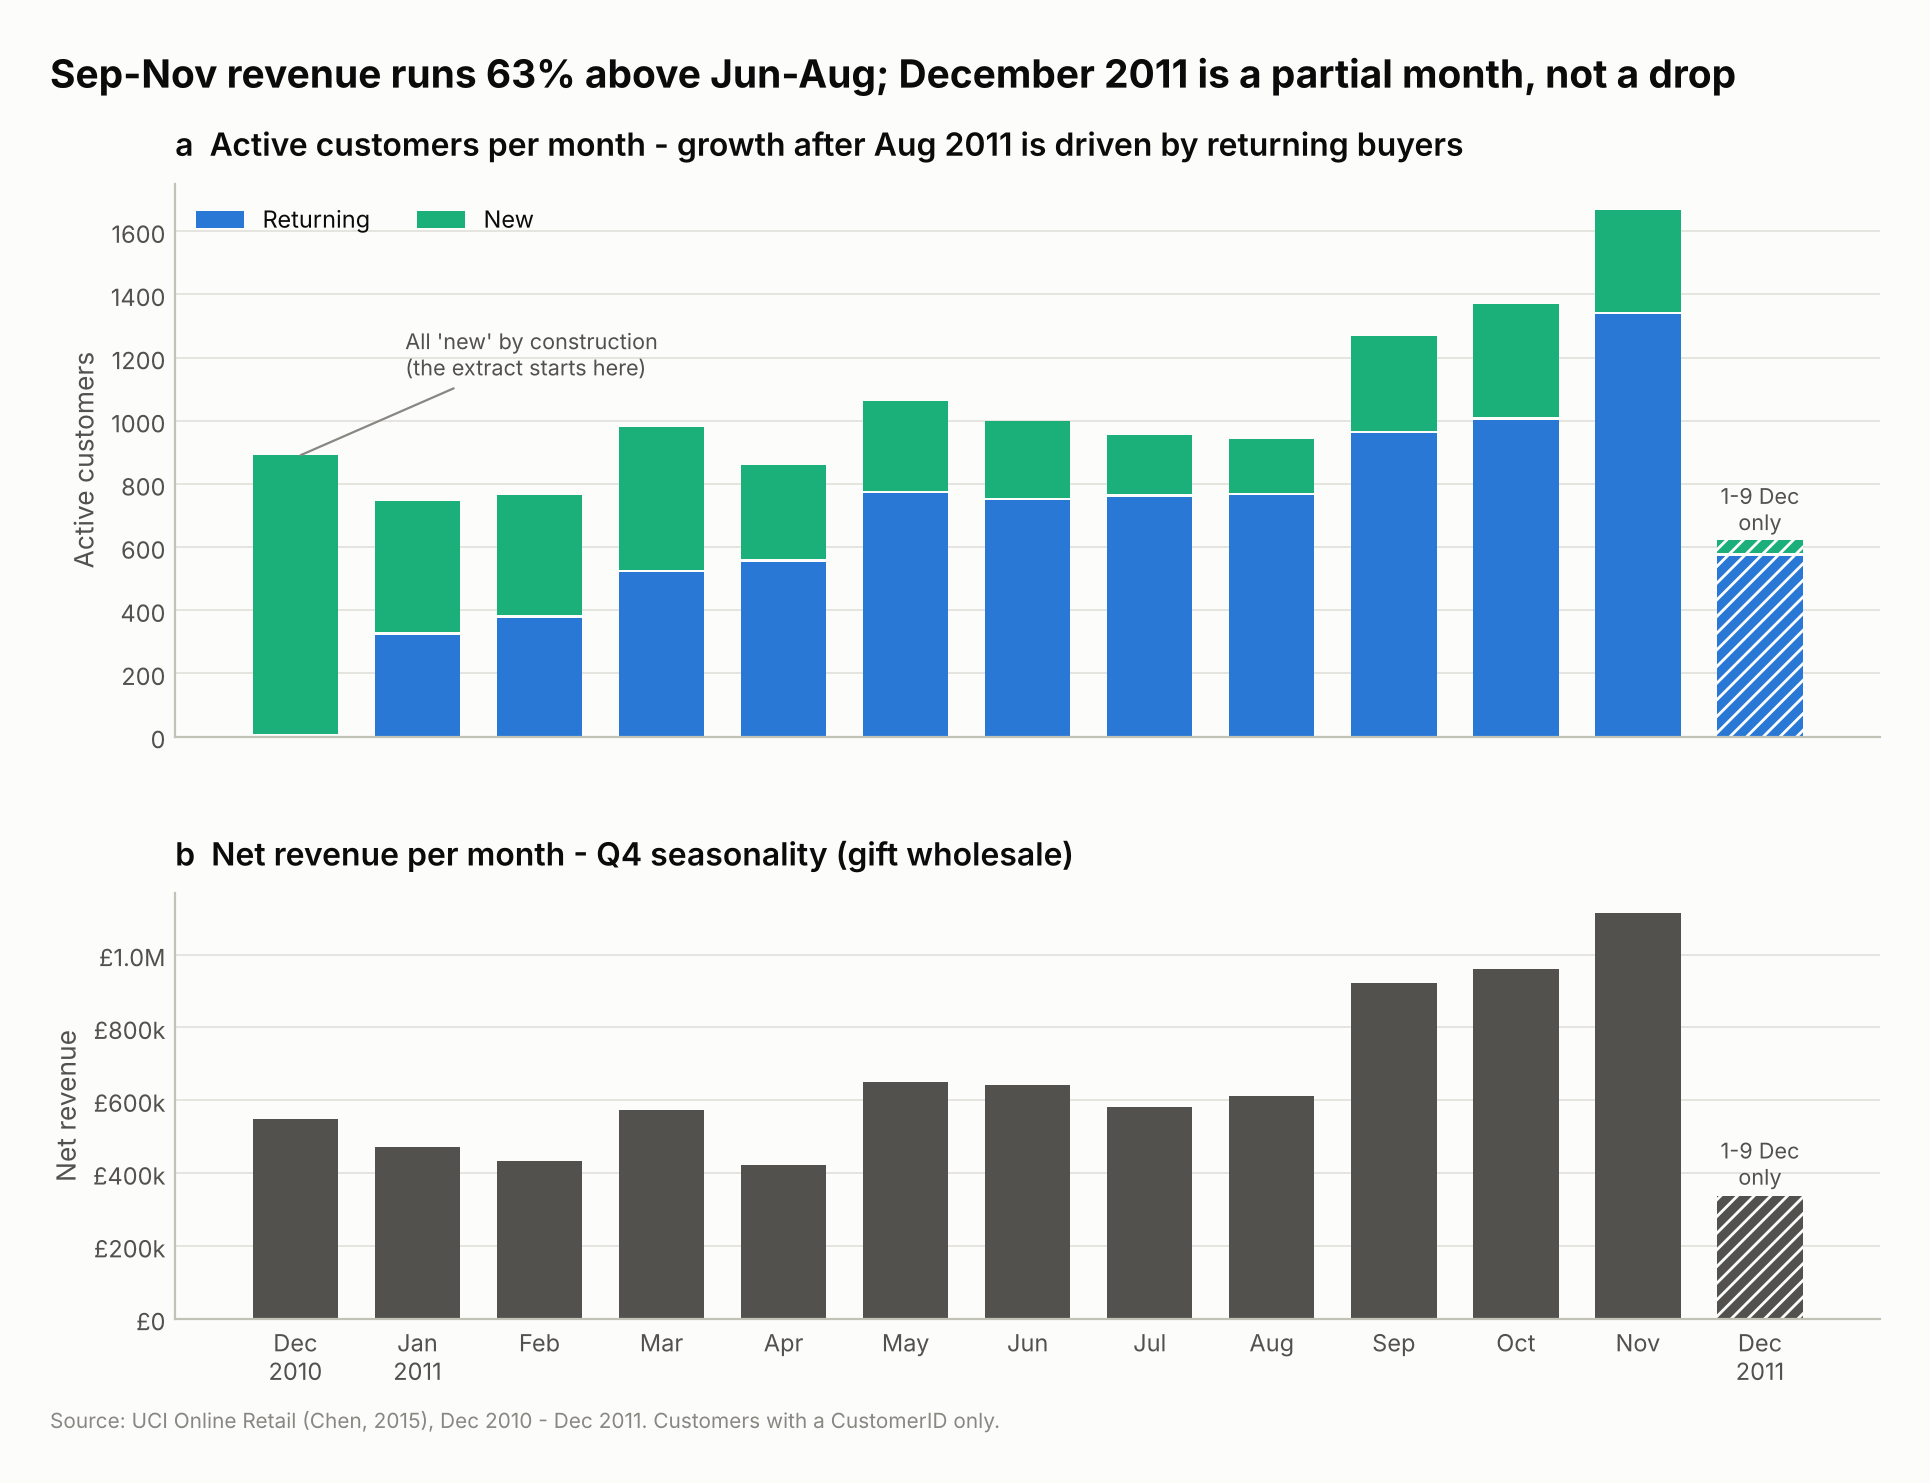

In [9]:
show(charts.fig_monthly_activity(res.monthly), "03_monthly_activity")

**解读**：9–11 月的净收入比 6–8 月高约 63%（礼品批发的圣诞备货季），增长主要来自**老客户回流**而非新客。2011 年 12 月只有 9 天数据，
任何按月的图都必须标注，否则会被误读为"断崖式下跌"。

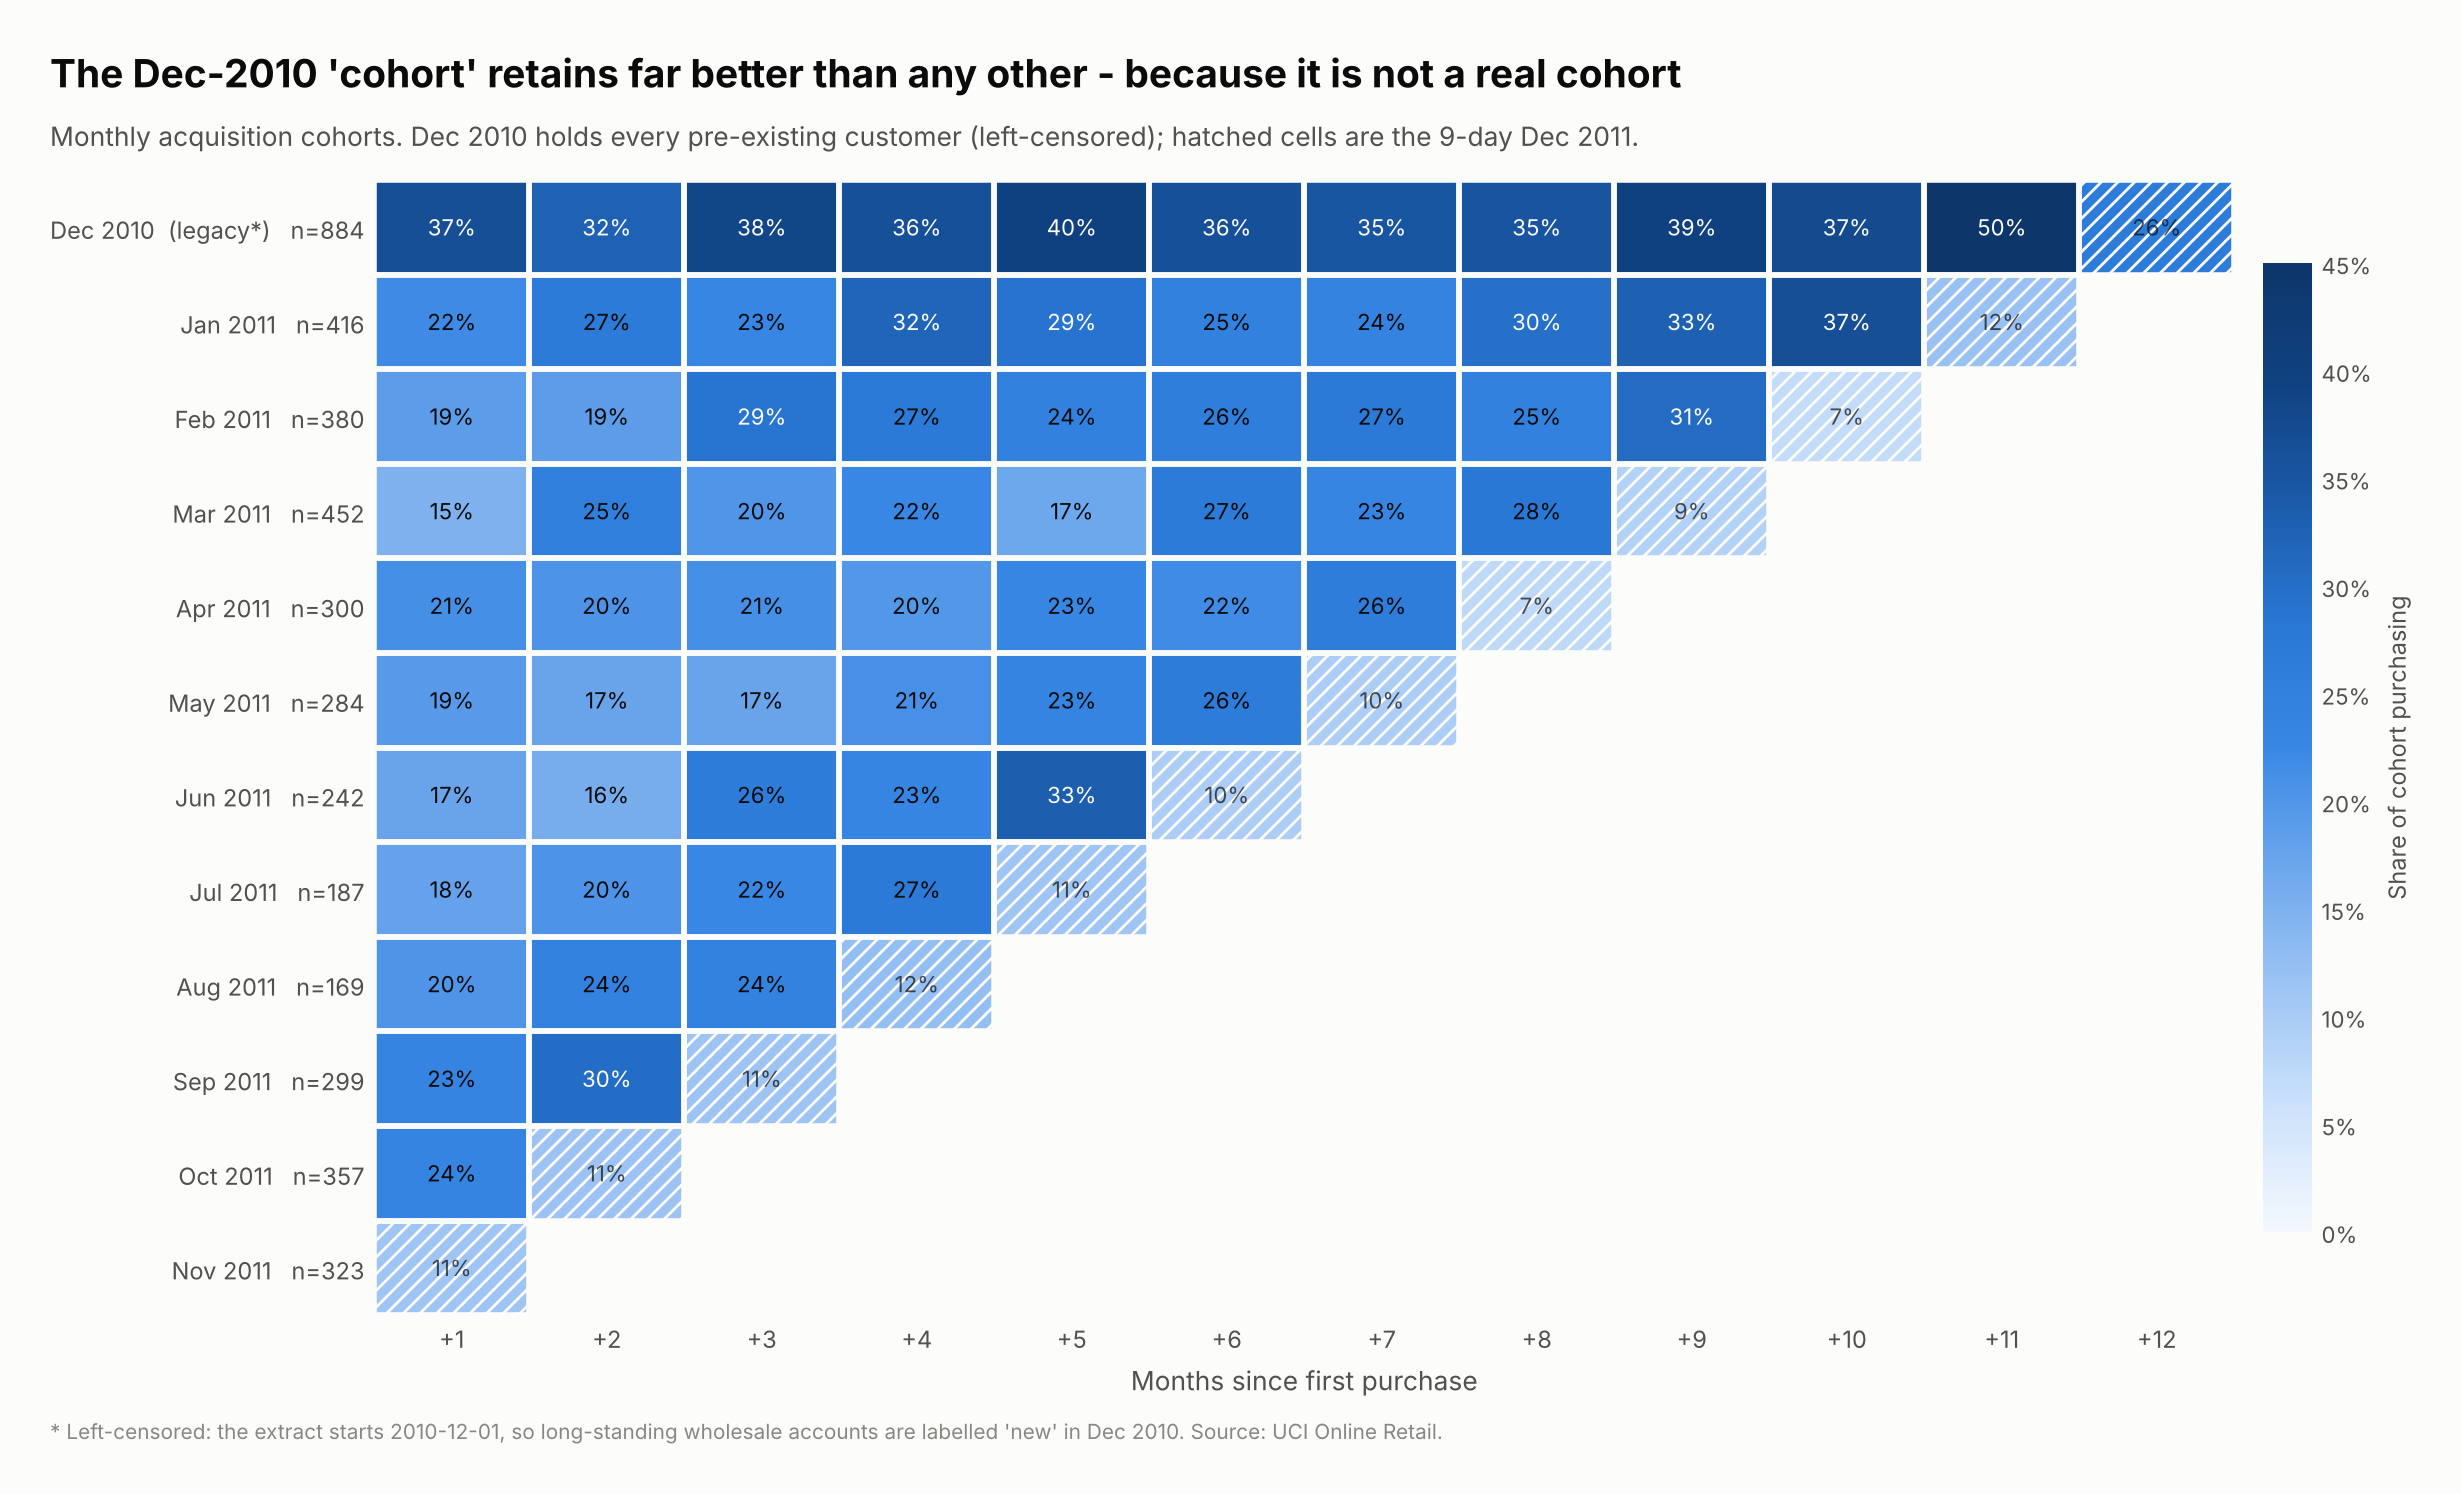

period,0,1,2,3,4,5,6
cohort,,,,,,,
2010-12,1.00,0.37,0.32,0.38,0.36,0.40,0.36
2011-01,1.00,0.22,0.27,0.23,0.32,0.29,0.25
2011-02,1.00,0.19,0.19,0.29,0.27,0.24,0.26
2011-03,1.00,0.15,0.25,0.20,0.22,0.17,0.27
2011-04,1.00,0.21,0.20,0.21,0.20,0.23,0.22
2011-05,1.00,0.19,0.17,0.17,0.21,0.23,0.26
2011-06,1.00,0.17,0.16,0.26,0.23,0.33,0.10
2011-07,1.00,0.18,0.20,0.22,0.27,0.11,NaN
2011-08,1.00,0.20,0.24,0.24,0.12,NaN,NaN


In [10]:
show(charts.fig_cohort_heatmap(res.retention, res.cohort_sizes), "04_cohort_retention_heatmap")
res.retention.iloc[:, :7].round(2)

**解读与批判**：

- 2010-12"队列"的留存率（35–50%）远高于其他队列（15–30%）。这**不是**因为 12 月获客质量高，而是**左删失**：数据从 2010-12-01 开始，
  所有早已存在的老批发客户都被标成了"12 月新客"。真正的获客队列从 2011-01 开始。
- 每条对角线的最后一格是只有 9 天的 2011-12，显著偏低，也不能解读为流失。
- 2011 年队列的 1 个月留存约 15–24%，之后并不单调下降，而是在第四季度回升——又是季节性。

## 6. 复购周期与"流失"的定义

非合约型业务里不存在"退订"事件，"流失"必须人为定义。这里不拍脑袋取 90 天，而是看**复购间隔的经验分布**：

In [11]:
g = res.gaps
print(f"复购间隔：中位数 {m['median_gap_days']:.0f} 天，P90 {m['p90_gap_days']:.0f} 天")
print("状态定义：Active = Recency ≤ 中位间隔；Cooling = 中位 ~ P90；Lapsed = > P90（比 90% 的真实复购间隔都长）")
res.customers['status'].value_counts()

复购间隔：中位数 28 天，P90 111 天
状态定义：Active = Recency ≤ 中位间隔；Cooling = 中位 ~ P90；Lapsed = > P90（比 90% 的真实复购间隔都长）


status
Active (<= 28d)      1527
Cooling (28-111d)    1523
Lapsed (> 111d)      1284
Name: count, dtype: int64

**注意**：28 / 111 天是把所有复购间隔**合并**后算的分位数，下单越频繁的客户贡献的间隔越多，所以阈值偏向高频客户的节奏。
若先算每位客户自己的中位间隔再取分位数，中位数约 52 天、P90 约 166 天。另外 13 个月的观察窗本身截断了很长的间隔。
这里选合并口径，是因为它回答的是"一次正常的复购通常隔多久"；对低频客户，111 天的"Lapsed"判定偏严格。

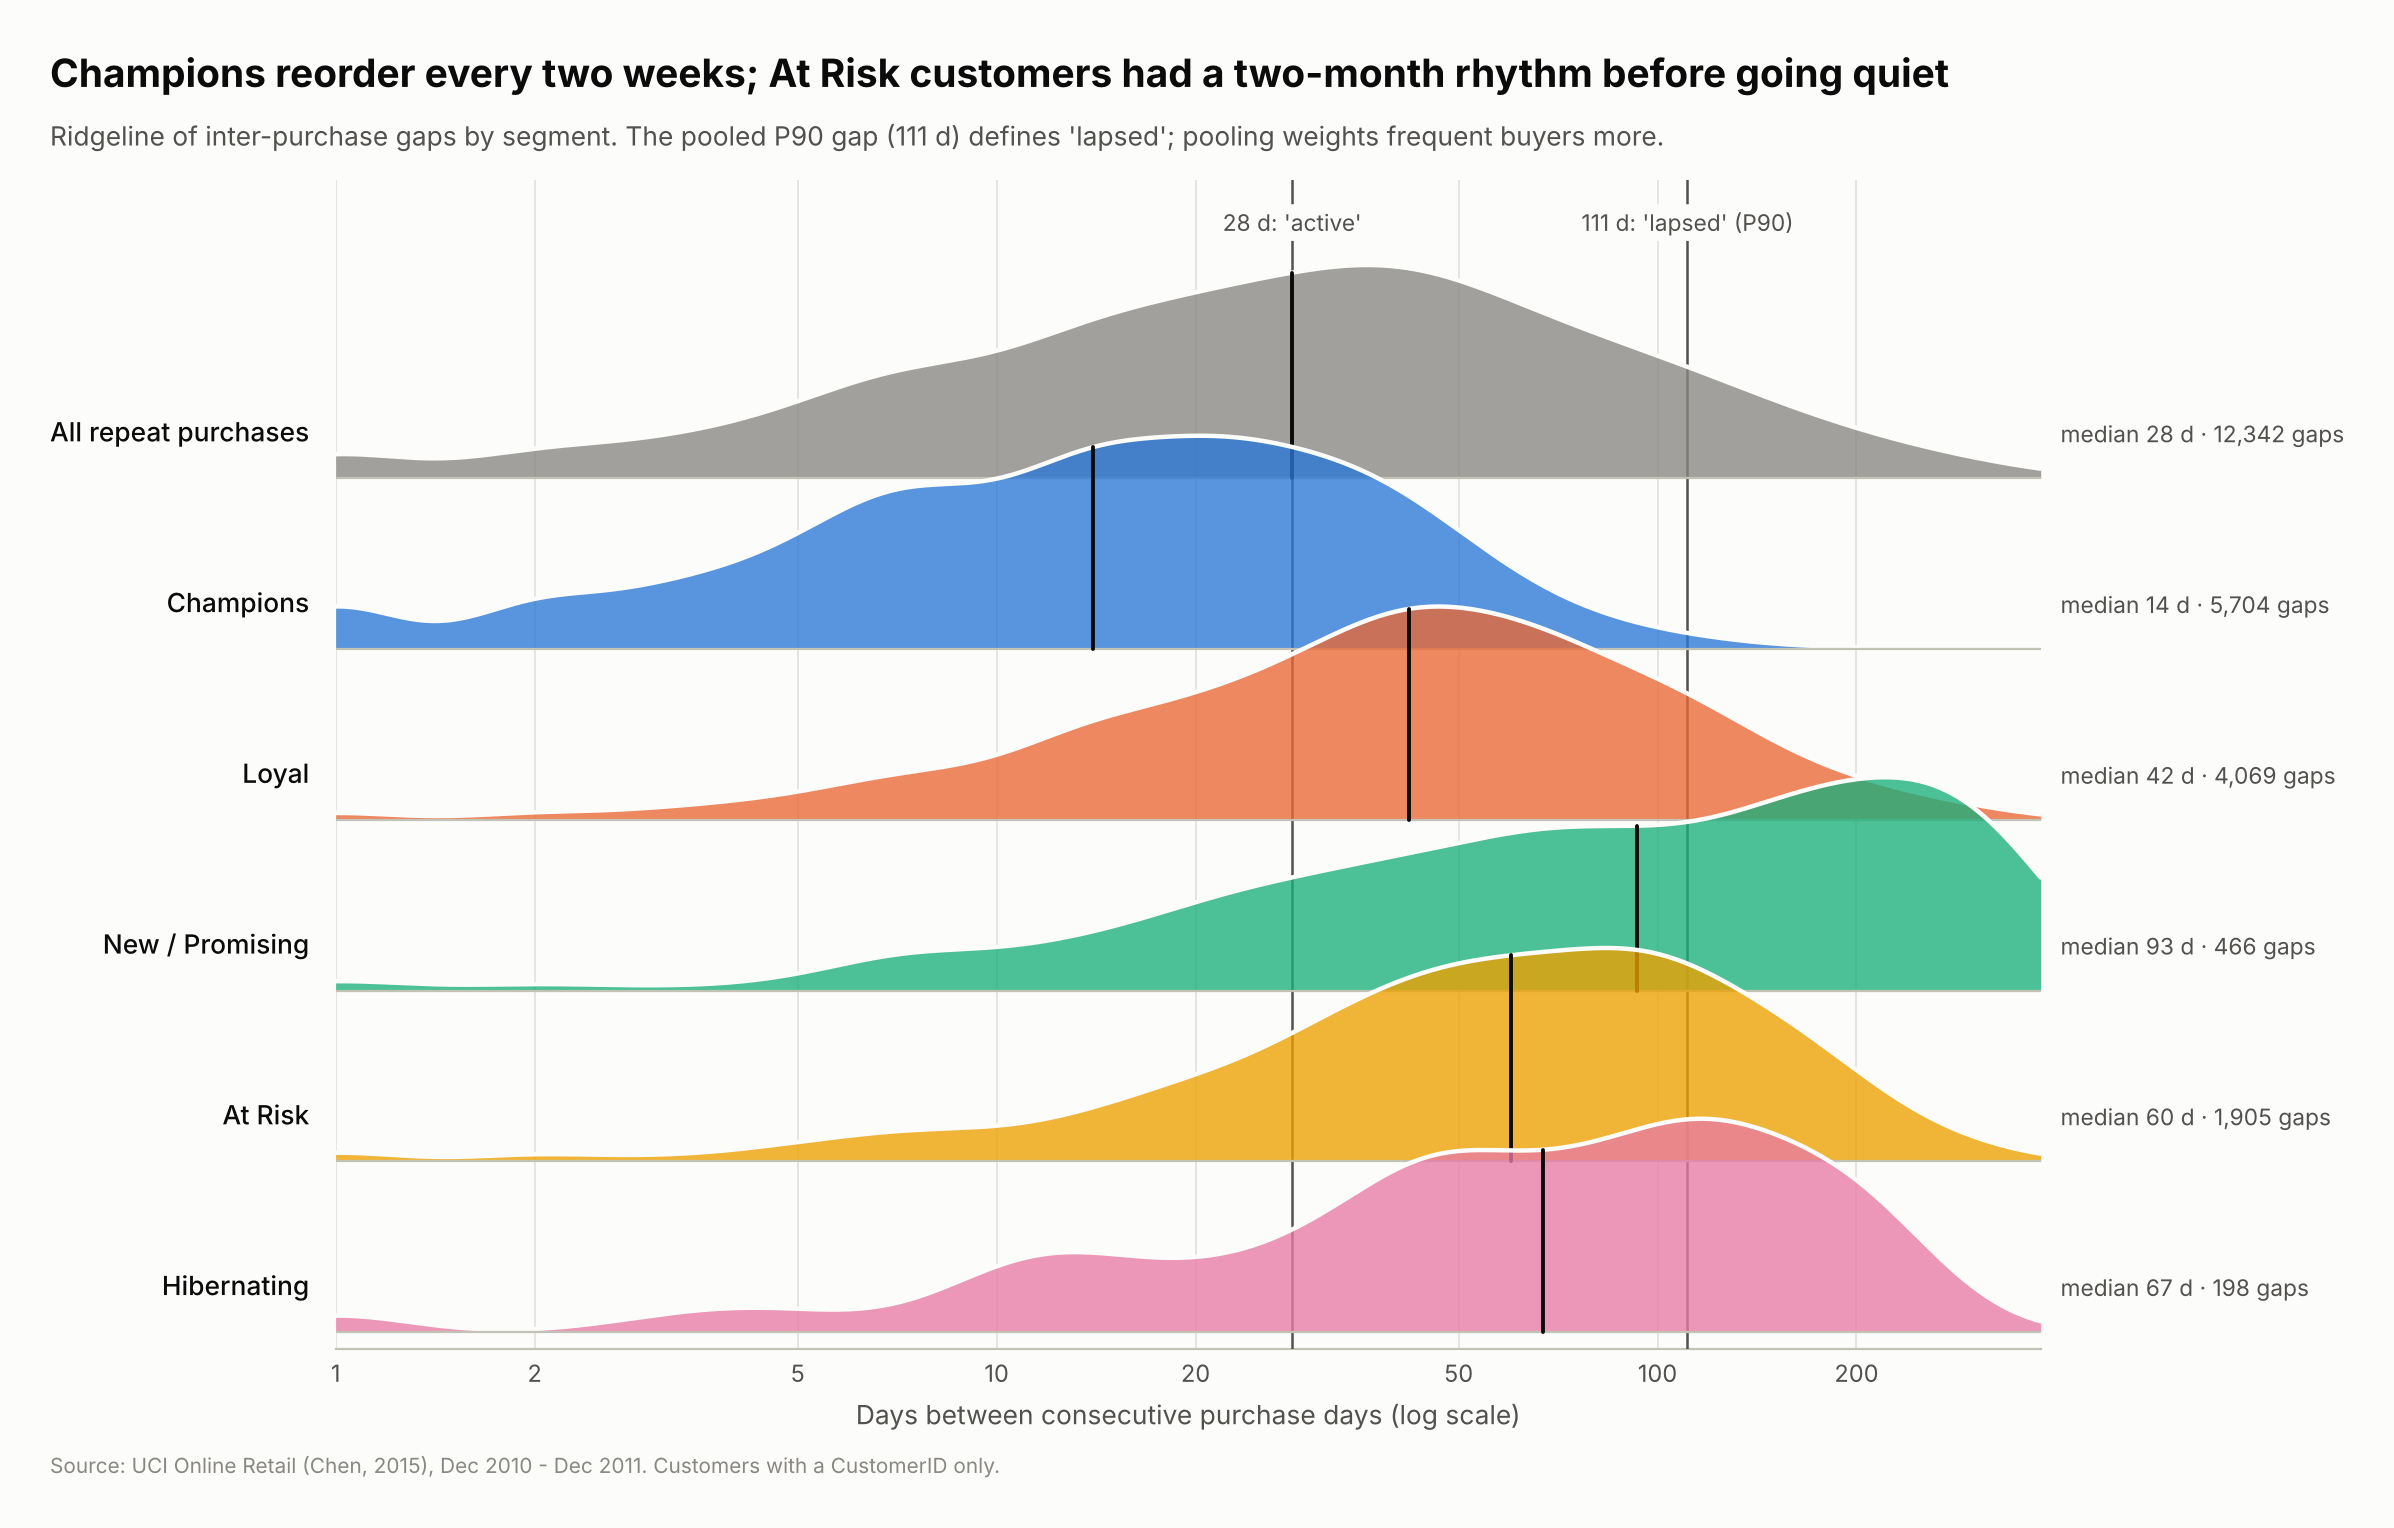

In [12]:
show(charts.fig_repurchase_ridgeline(g[g['segment'].isin(charts.SEGMENT_ORDER)], m['median_gap_days'], m['p90_gap_days']),
     "11_repurchase_ridgeline")

## 7. K-means 分群

### 7.1 预处理与选 k

RFM 三个维度先 `log1p` 再标准化（`rfm.segmentation.make_scaler`），净消费 ≤ 0 的 12 位客户（全部退货）不参与聚类。
对 k = 2…8 计算 Silhouette、Davies-Bouldin、Calinski-Harabasz，以及 **bootstrap 稳定性**（20 次重抽样重新聚类，与全量解的 ARI）。

In [13]:
res.k_selection.round(3)

,inertia,silhouette,calinski_harabasz,davies_bouldin,stability_ari,stability_ari_p05
k,,,,,,
2,"6,465.79",0.43,"4,343.01",0.89,0.98,0.94
3,"4,848.03",0.34,"3,616.10",1.04,0.93,0.88
4,"3,919.18",0.33,"3,322.51",1.02,0.87,0.70
5,"3,269.22",0.32,"3,201.15",0.98,0.88,0.67
6,"2,843.63",0.31,"3,072.78",1.02,0.84,0.74
7,"2,537.26",0.30,"2,955.97",0.99,0.85,0.80
8,"2,331.39",0.30,"2,811.19",0.99,0.68,0.49


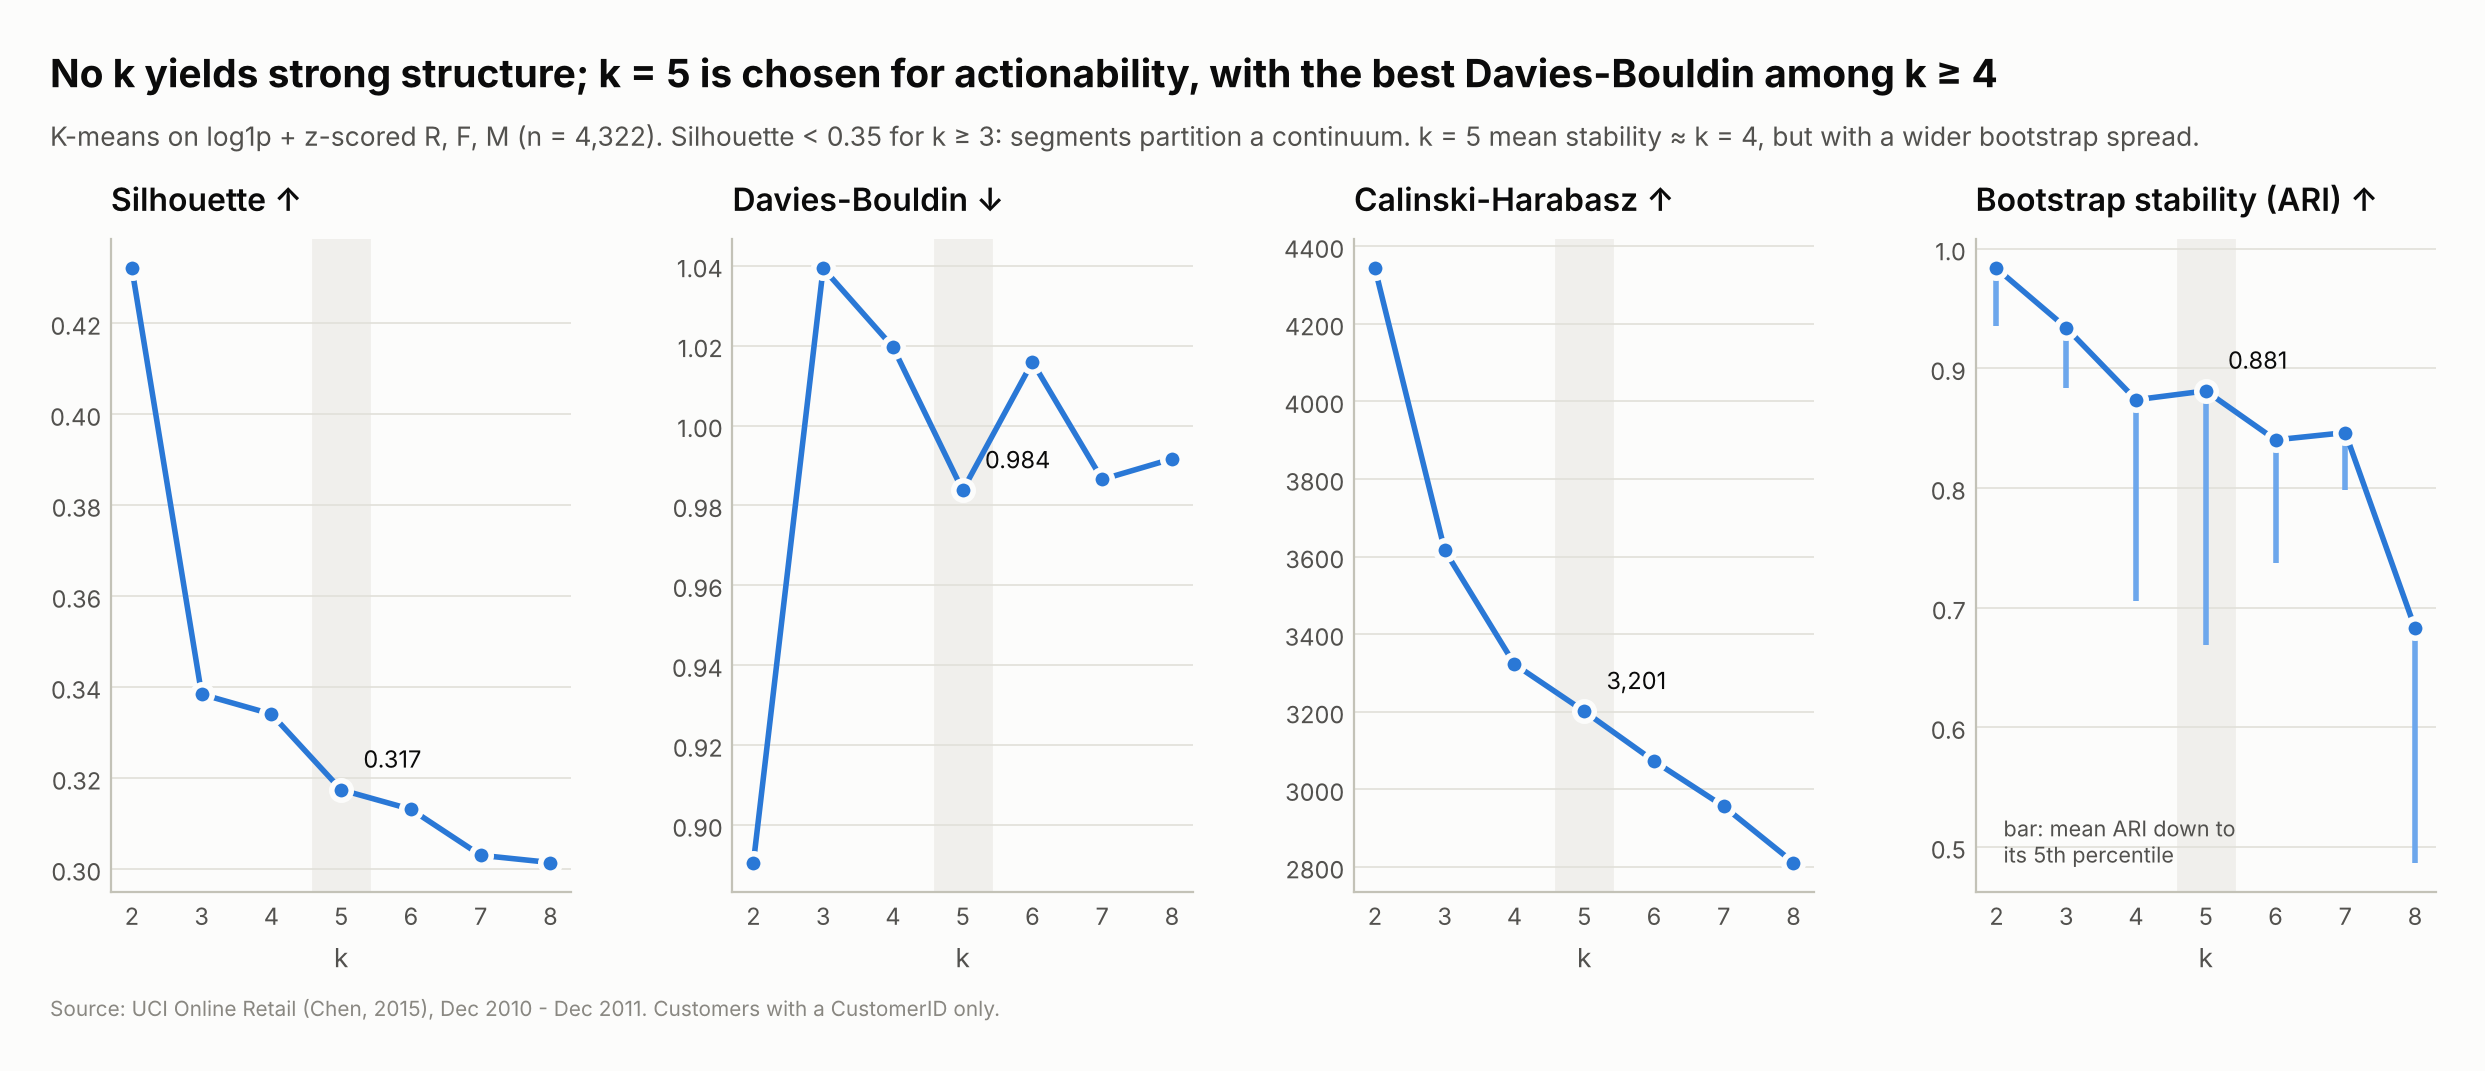

In [14]:
show(charts.fig_k_selection(res.k_selection), "05_k_selection")

**选择 k = 5 的理由（以及它的边界）**：

- Silhouette 在 k ≥ 3 时都只有 0.30–0.34：**RFM 空间是一个连续体，不存在天然分离的簇**。分群是为了行动而做的切分，不是"发现"了自然群体——这一点必须写进结论。
- k = 2 指标最好，但只能区分"好/坏"，没有业务价值。
- 在 k ≥ 4 中，k = 5 的 Davies-Bouldin 最低；平均 bootstrap ARI 0.88，与 k = 4（0.87）相当，但 5% 分位数更低（0.67 vs 0.70），说明边界上的客户在重抽样中会换组。
- 选 k = 5 主要是为了**可操作性**：它是唯一单独分出 **"At Risk"（曾经中等价值、正在沉寂）** 的解——这正是挽留动作的目标人群。

In [15]:
seg = res.customers[res.customers['segment'].isin(charts.SEGMENT_ORDER)]
summary = seg.groupby('segment', observed=True).agg(
    customers=('frequency', 'size'),
    median_recency=('recency_days', 'median'),
    median_orders=('frequency', 'median'),
    median_net_spend=('monetary', 'median'),
    revenue=('monetary', 'sum'),
)
summary['revenue_share'] = summary['revenue'] / summary['revenue'].sum()
summary

,customers,median_recency,median_orders,median_net_spend,revenue,revenue_share
segment,,,,,,
Champions,357,8.00,15.00,"5,656.75","4,408,031.87",0.53
Loyal,965,17.00,5.00,"1,682.08","1,948,568.59",0.24
New / Promising,873,26.00,1.00,332.64,"319,372.16",0.04
At Risk,1000,84.00,3.00,963.78,"1,297,943.83",0.16
Hibernating,1127,219.00,1.00,232.60,"295,720.87",0.04


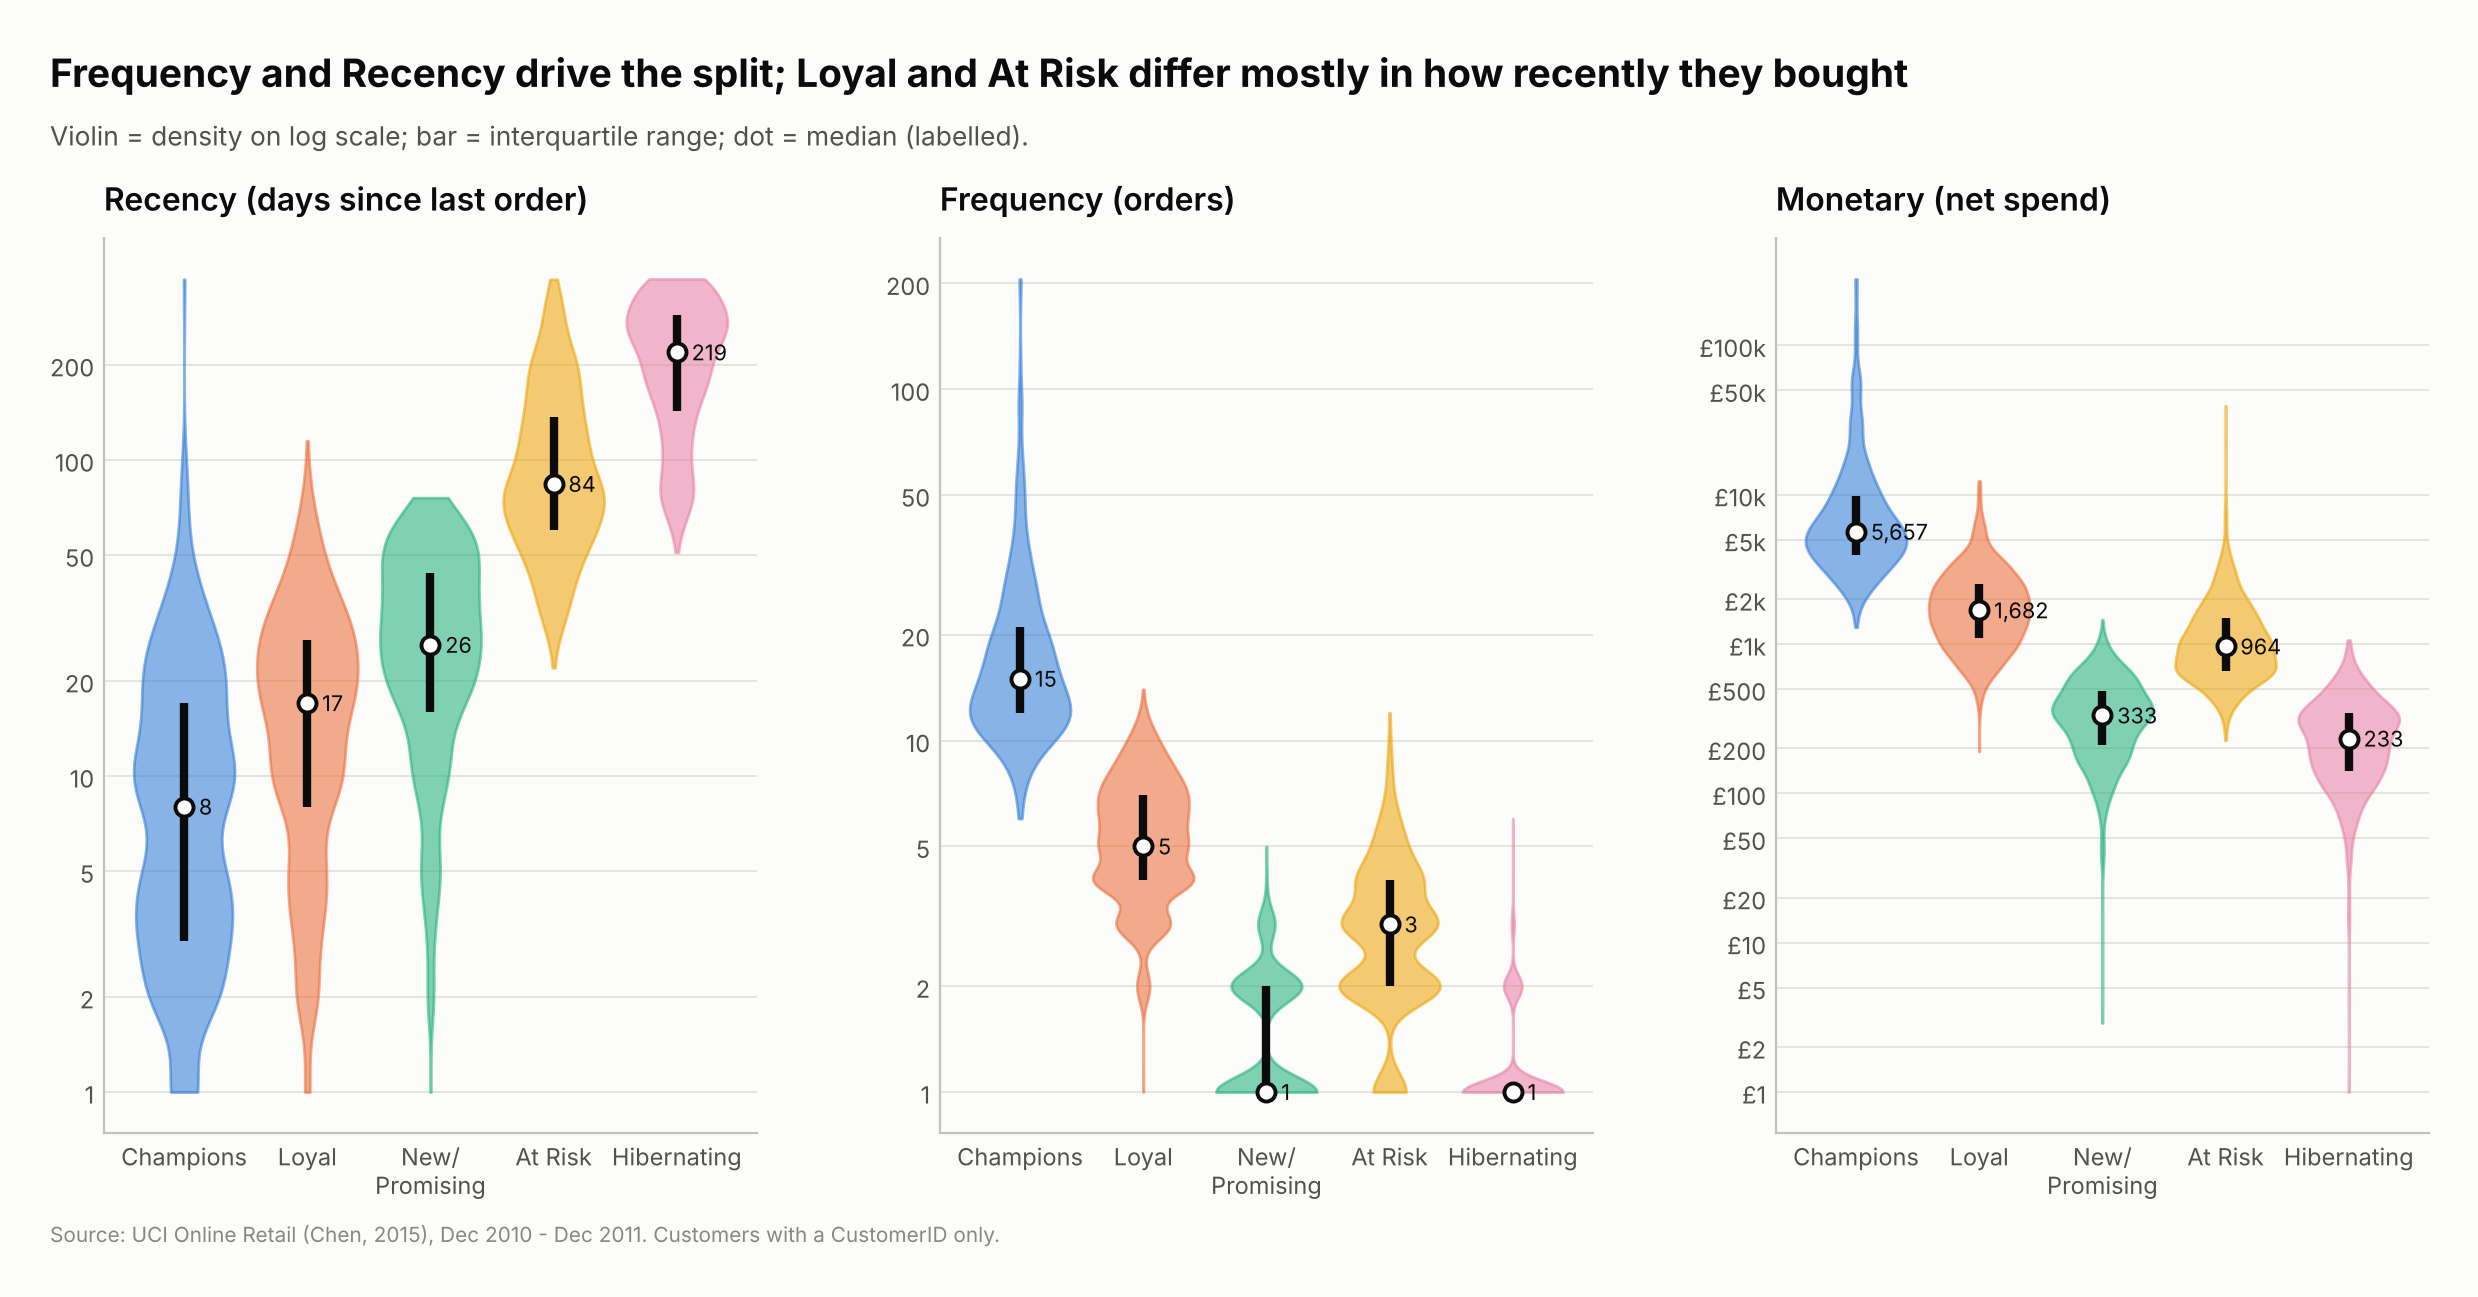

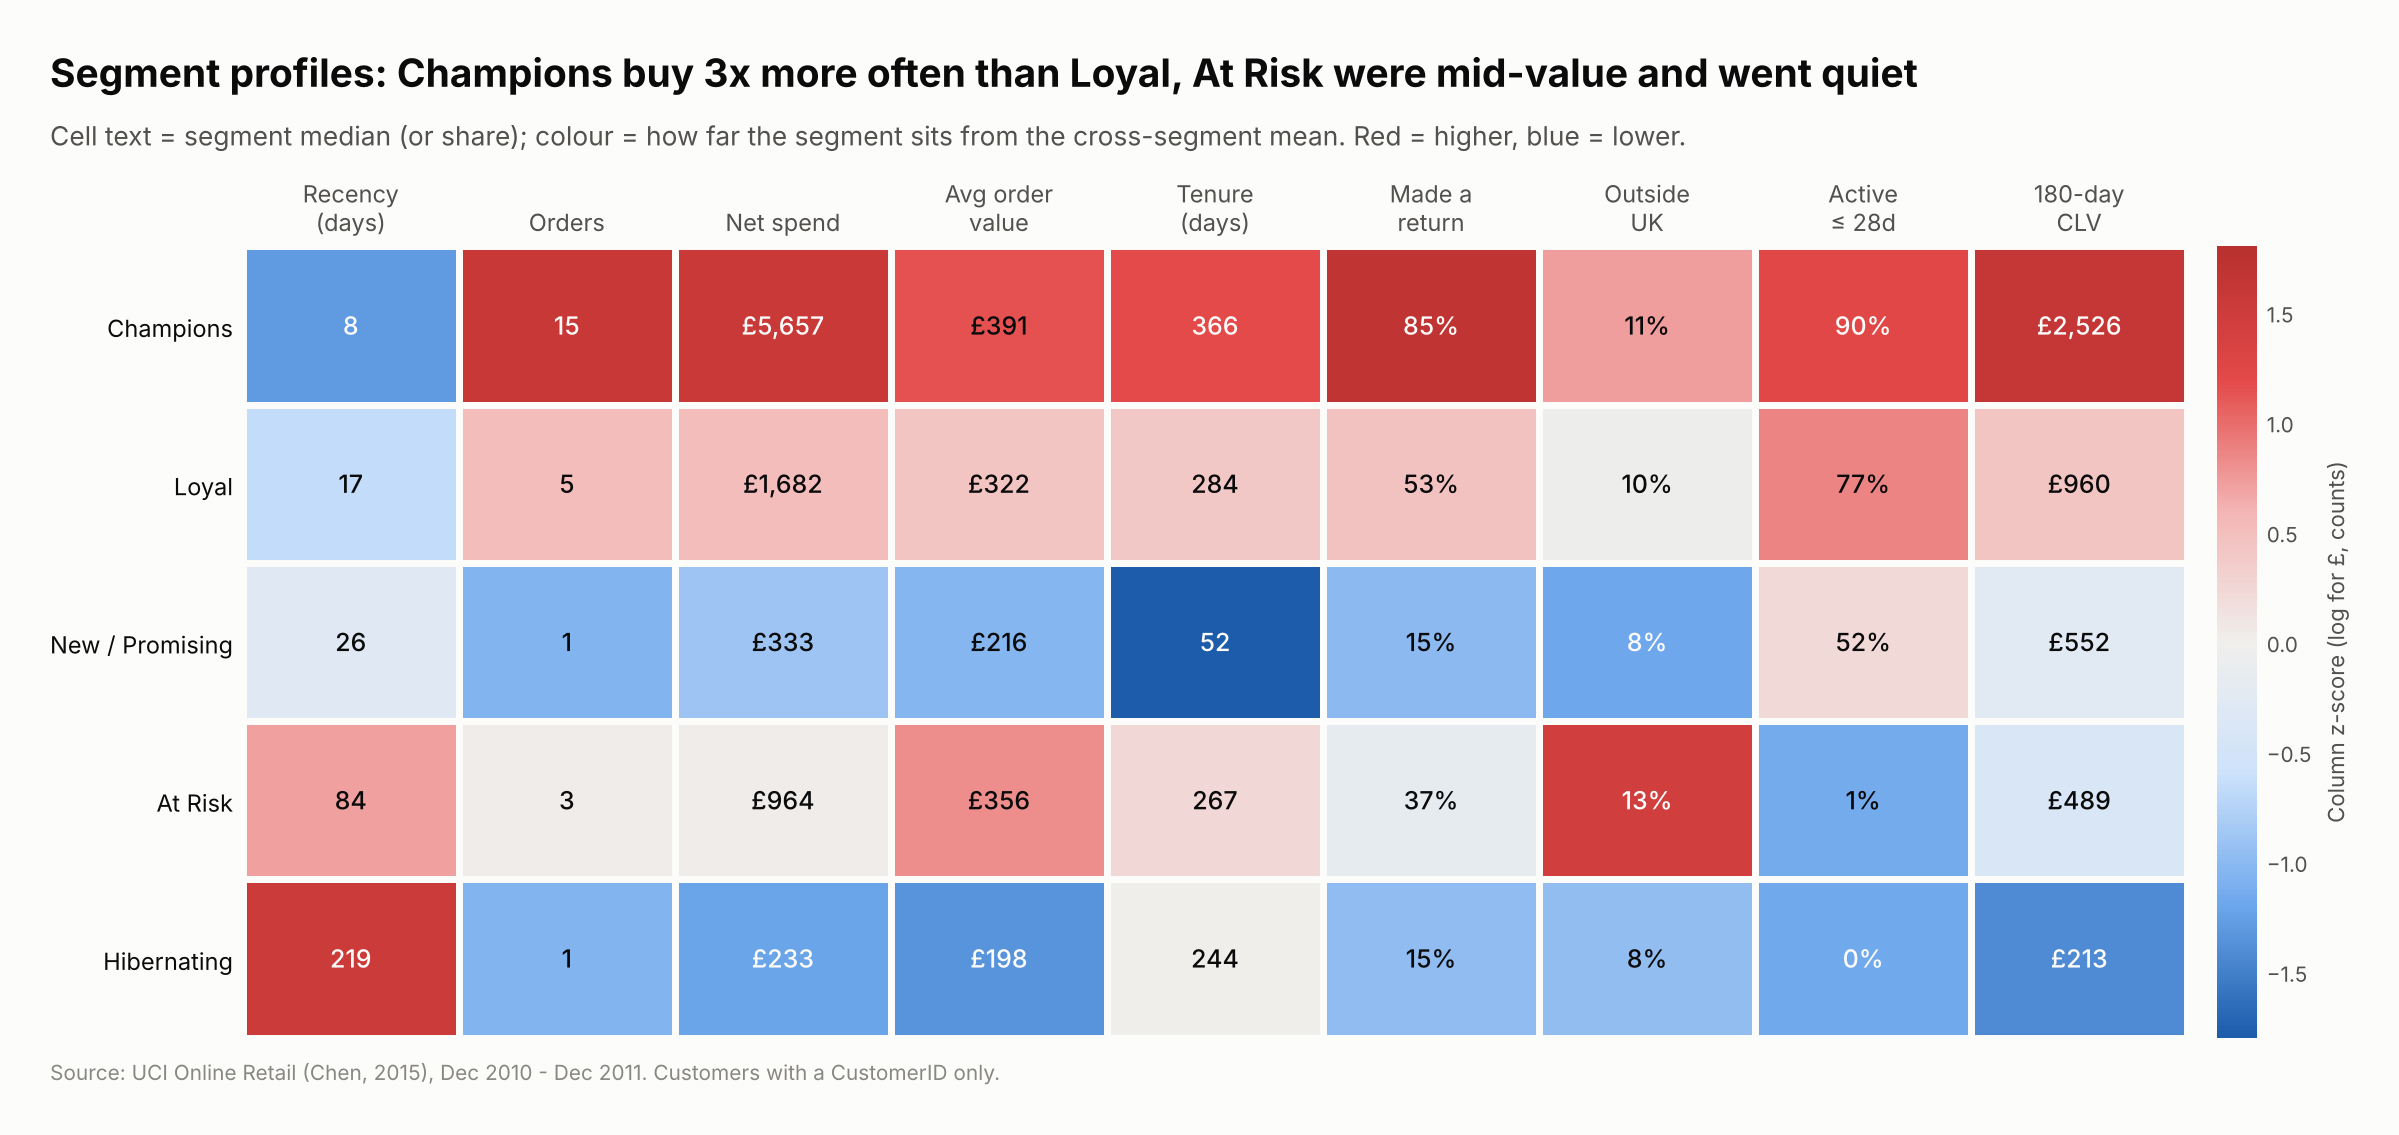

In [16]:
show(charts.fig_segment_violins(res.customers), "06_segment_violins")
show(charts.fig_segment_profile(res.customers), "07_segment_profile_heatmap")

### 7.2 把聚类翻译成业务规则：代理决策树

K-means 的中心在"对数-标准化"空间里，业务方无法直接使用。用一棵深度 3 的决策树在**原始单位**（天、单数、英镑）上拟合聚类标签，
5 折交叉验证的**保真度**（tree 预测 = K-means 标签的比例）衡量这套规则能多大程度替代模型。

代理树保真度 (5-fold CV) = 84.2%


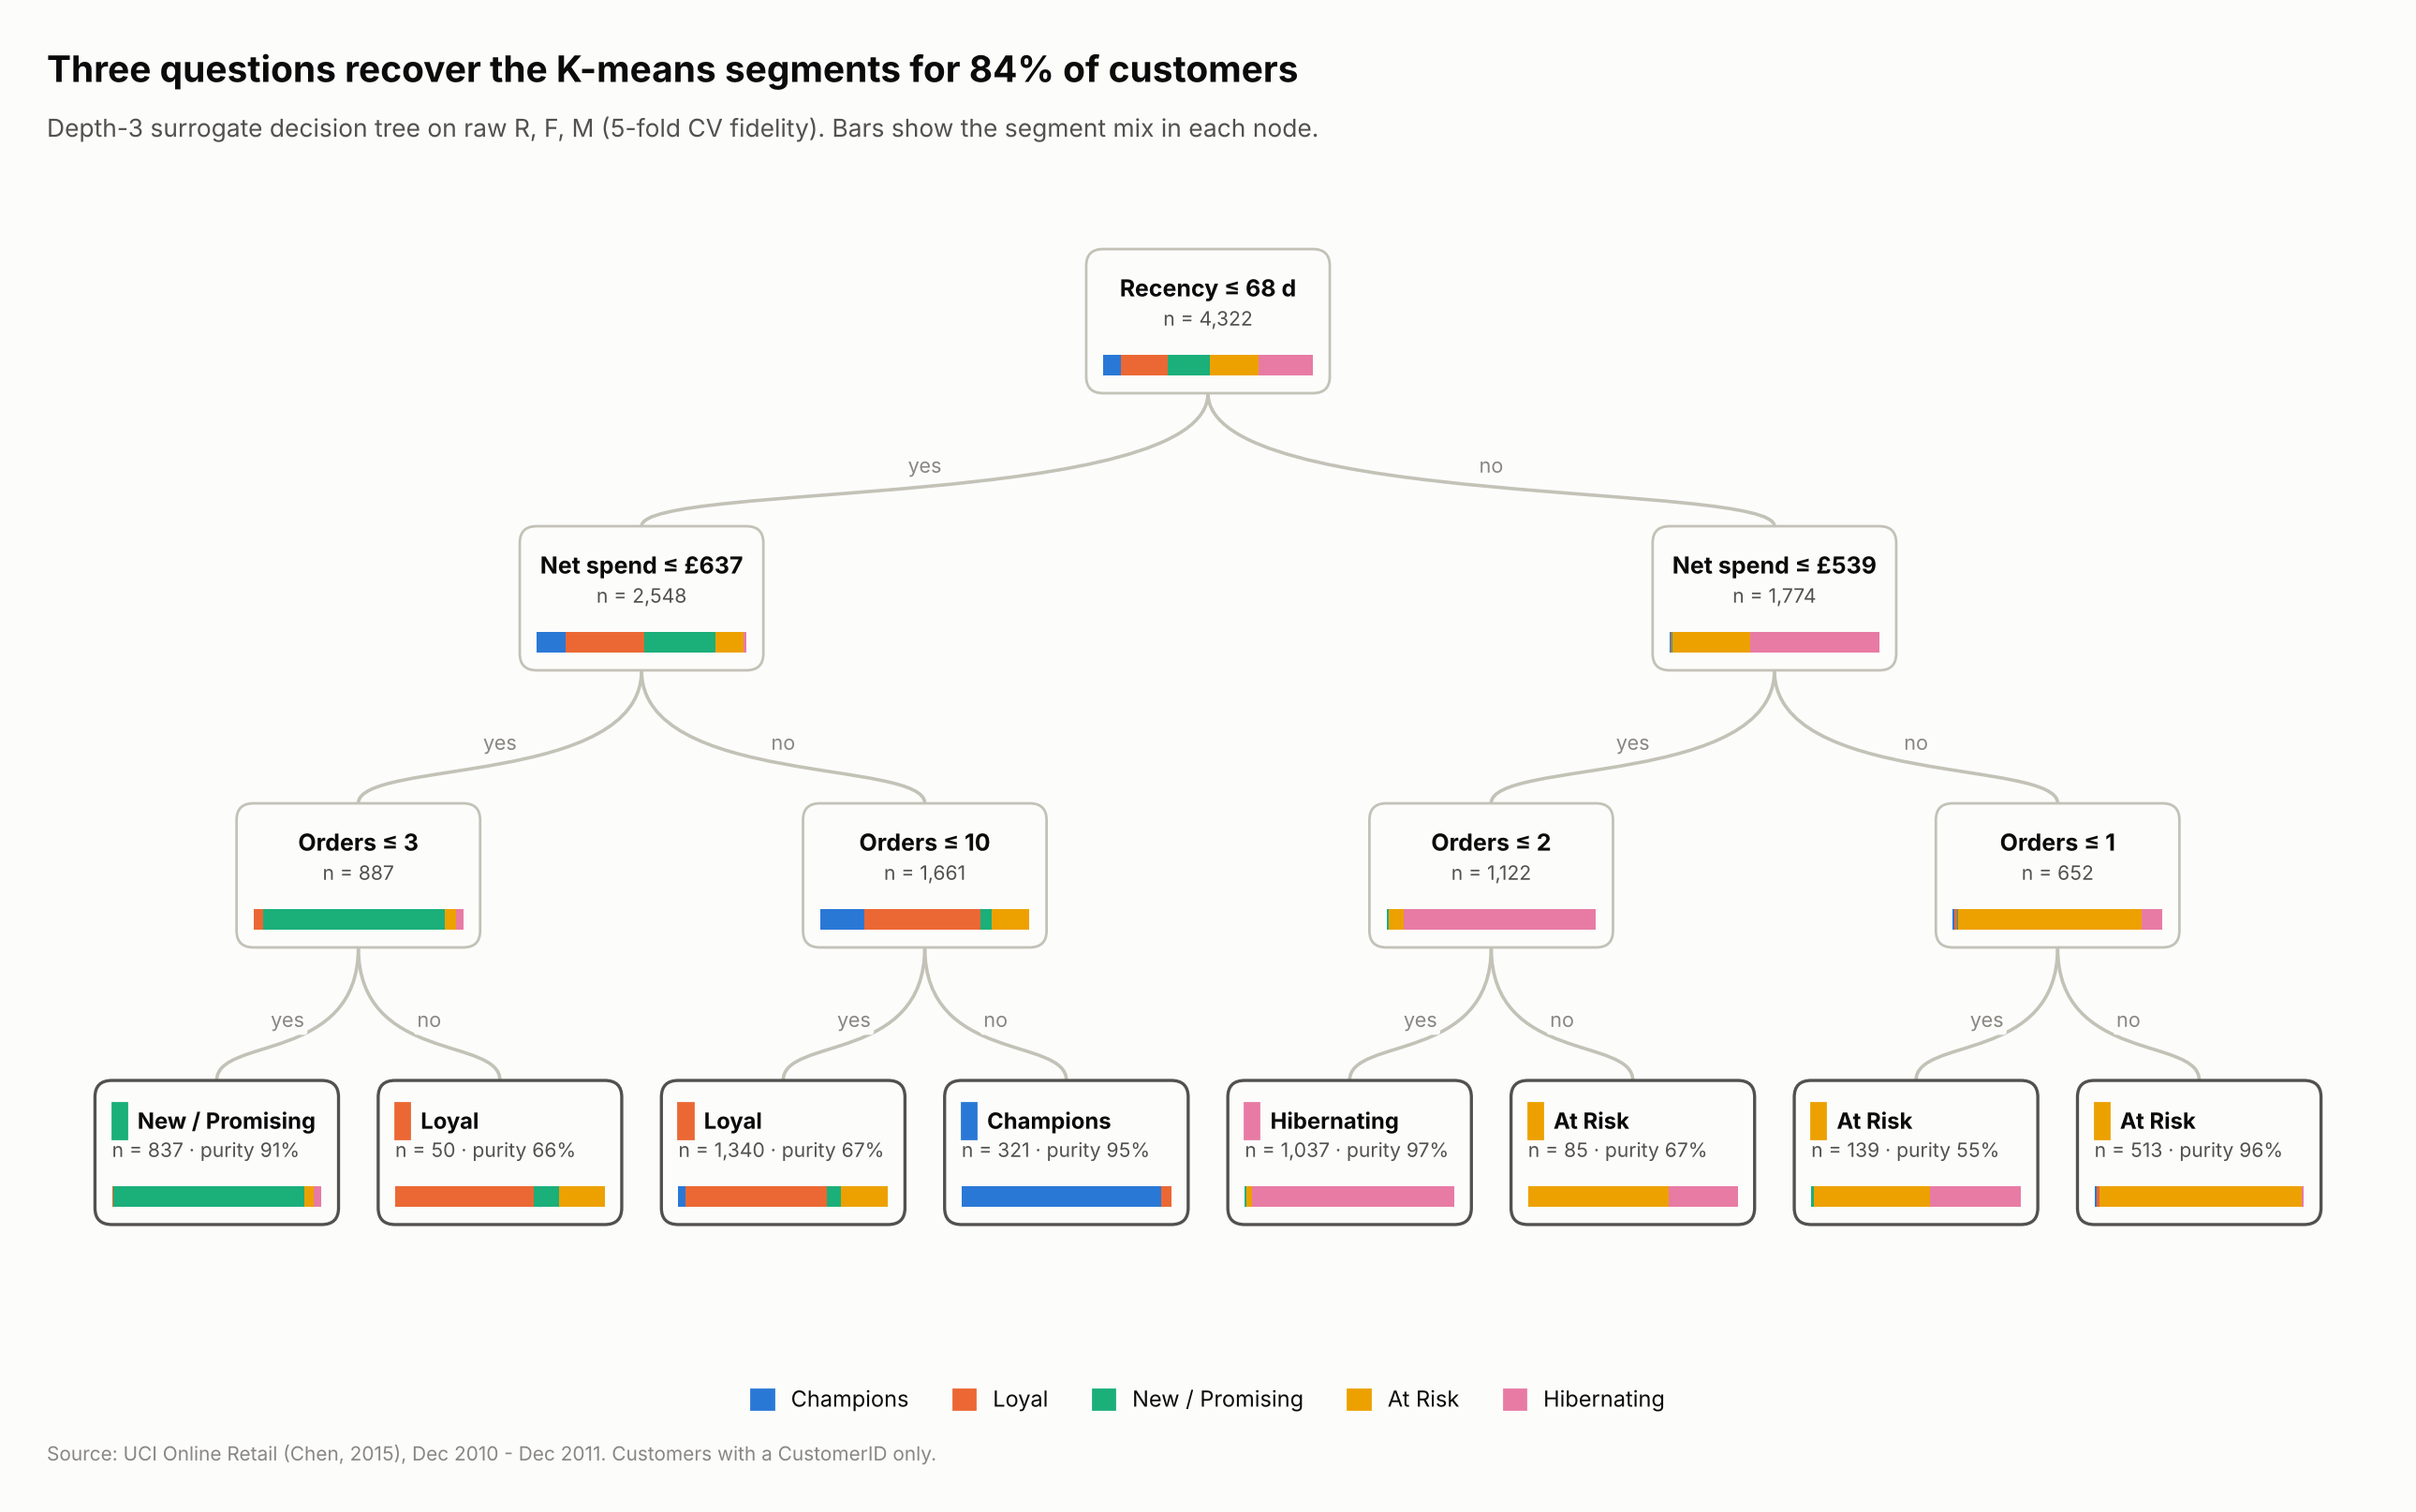

In [17]:
print(f"代理树保真度 (5-fold CV) = {res.tree_fidelity:.1%}")
show(charts.fig_segment_tree(res.tree, res.tree_fidelity), "08_segment_decision_tree")

### 7.3 与经典规则型 RFM 对照

经典做法：R、F 各打 1–5 分（分位数），再查一张 R×F 的命名表（Champions、Loyal、At Risk、Hibernating……）。
注意 Frequency 有大量并列值（35% 客户 F = 1）：任何分位数切分都只能任意打破并列，让完全相同的客户拿到不同的分数。所以 F 用固定的业务分箱 1 / 2 / 3–4 / 5–8 / 9+ 单；R、M 用原始值的五分位。

Adjusted Mutual Information (K-means vs 规则 RFM) = 0.52


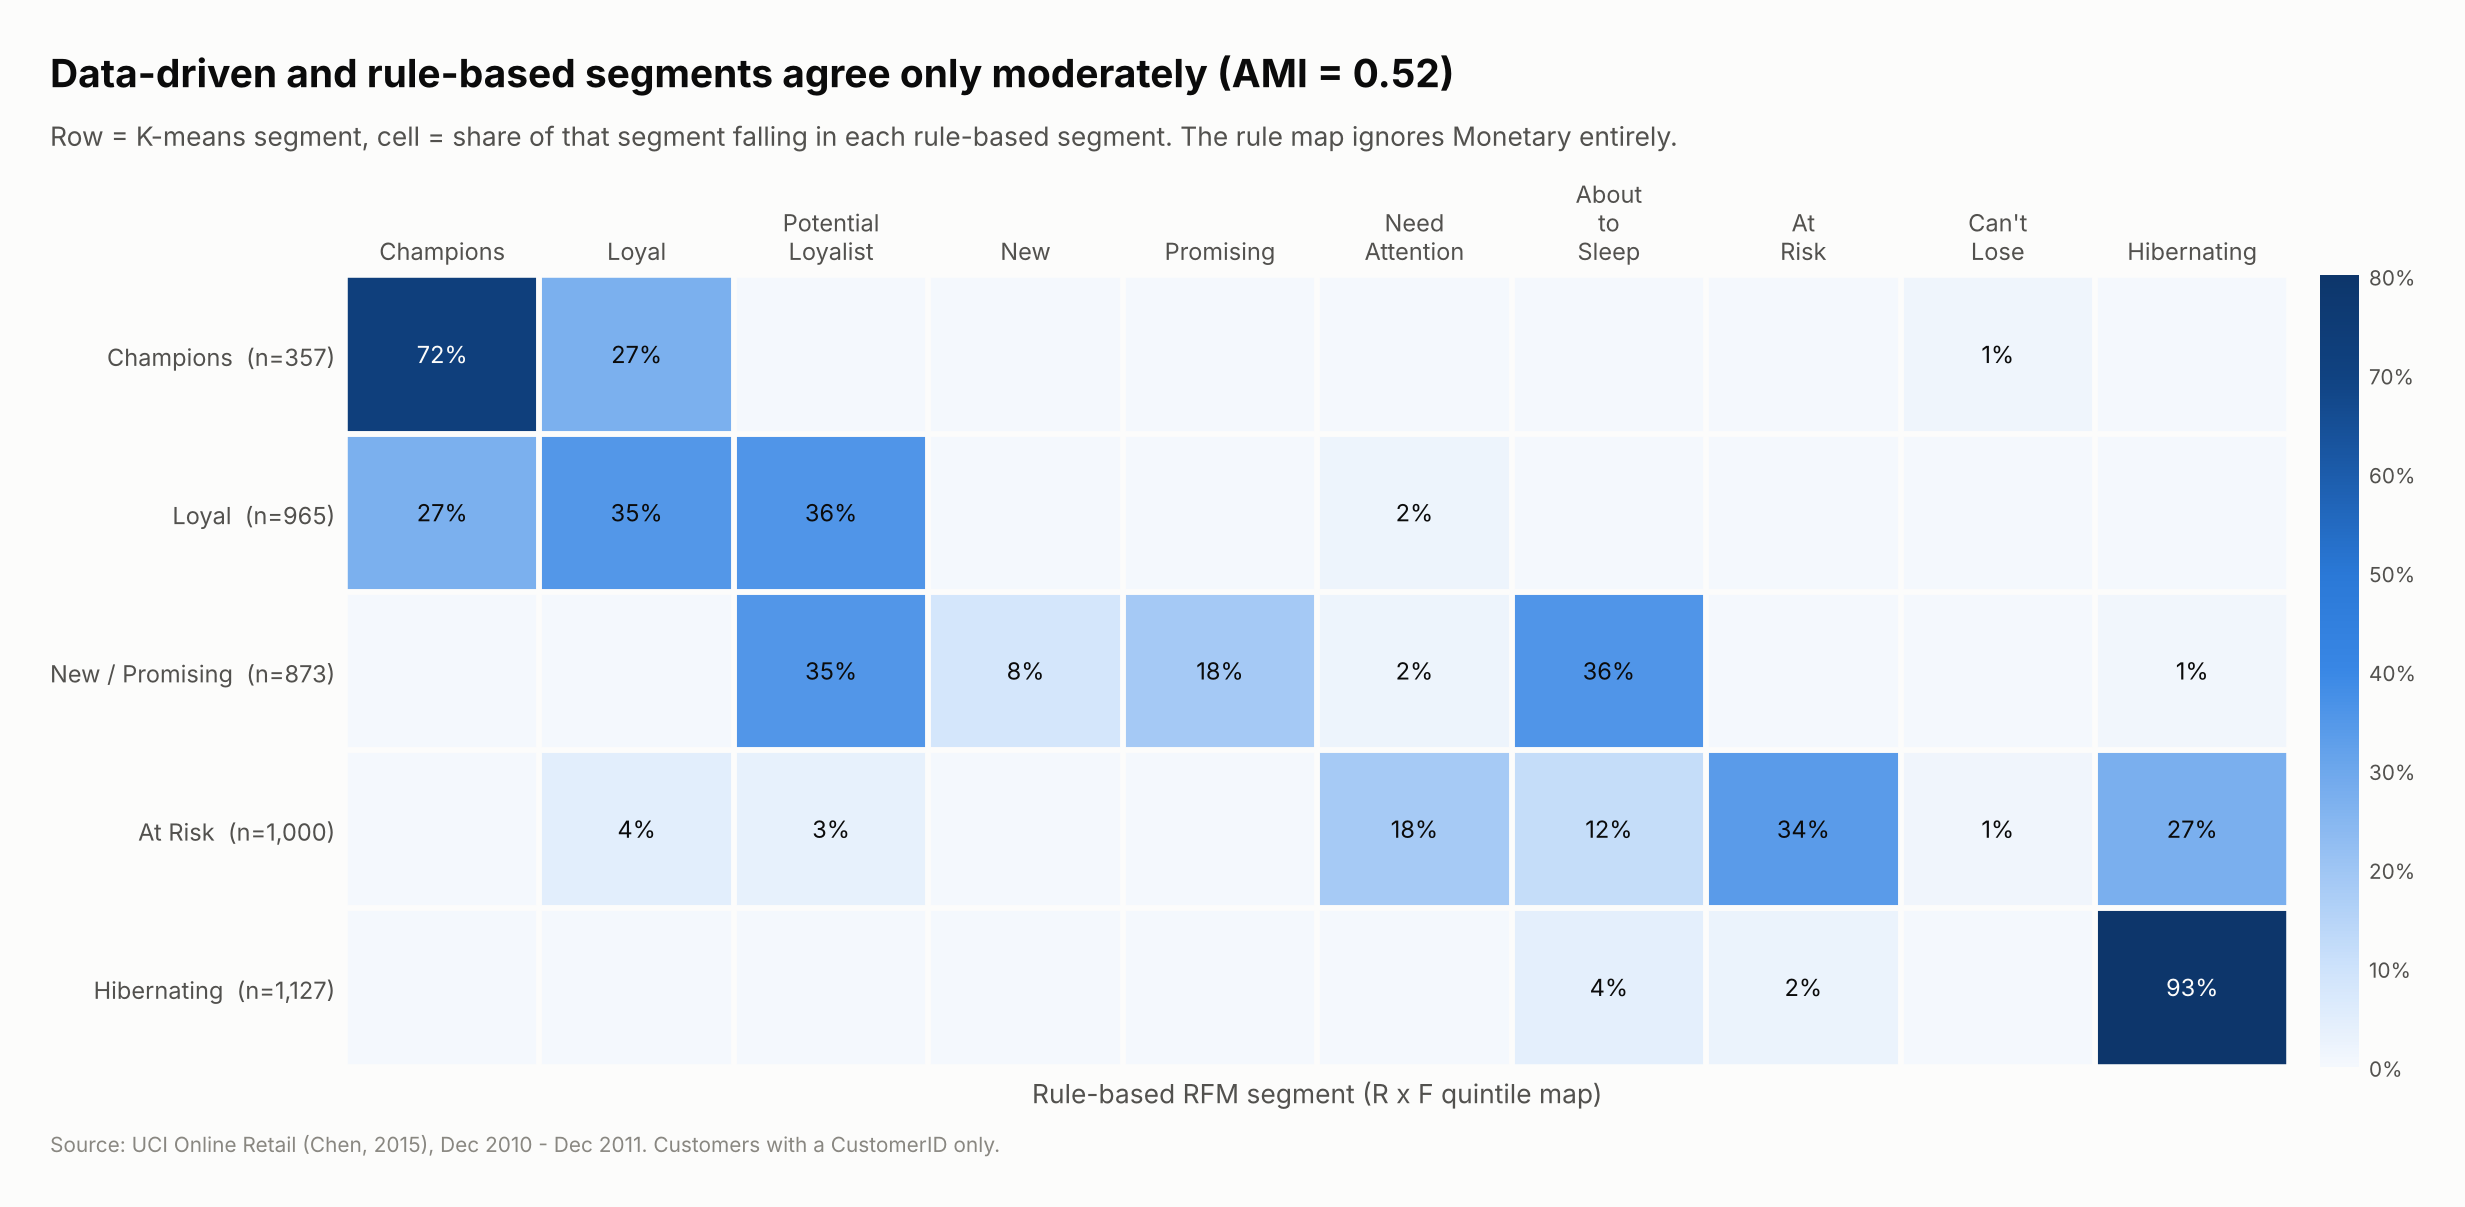

In [18]:
print(f"Adjusted Mutual Information (K-means vs 规则 RFM) = {m['kmeans_vs_rfm_ami']:.2f}")
show(charts.fig_kmeans_vs_rules(res.customers, m['kmeans_vs_rfm_ami']), "09_kmeans_vs_rfm_rules")

**解读**：两种方法在两端（Champions、Hibernating）高度一致，在中间地带分歧明显。原因之一是规则表**完全不看 Monetary**：
K-means 的 "Loyal" 有 27% 被规则表叫作 "Champions"——他们最近买过、单数不少，但金额明显低于 K-means 的 Champions。哪种更"对"取决于用途：
规则表透明、可复用；K-means 同时考虑了金额。项目里两者都保留在 `customers.csv` 中。

## 8. 行为交集（UpSet）

六个可解释的行为标签：消费前 20%、复购客户、近期下单（≤ 中位间隔）、沉寂（> P90）、有退货、海外。
UpSet 图展示的是**精确组合**（每列是一种组合），并给出每种组合的收入占比——比维恩图能承载更多集合。

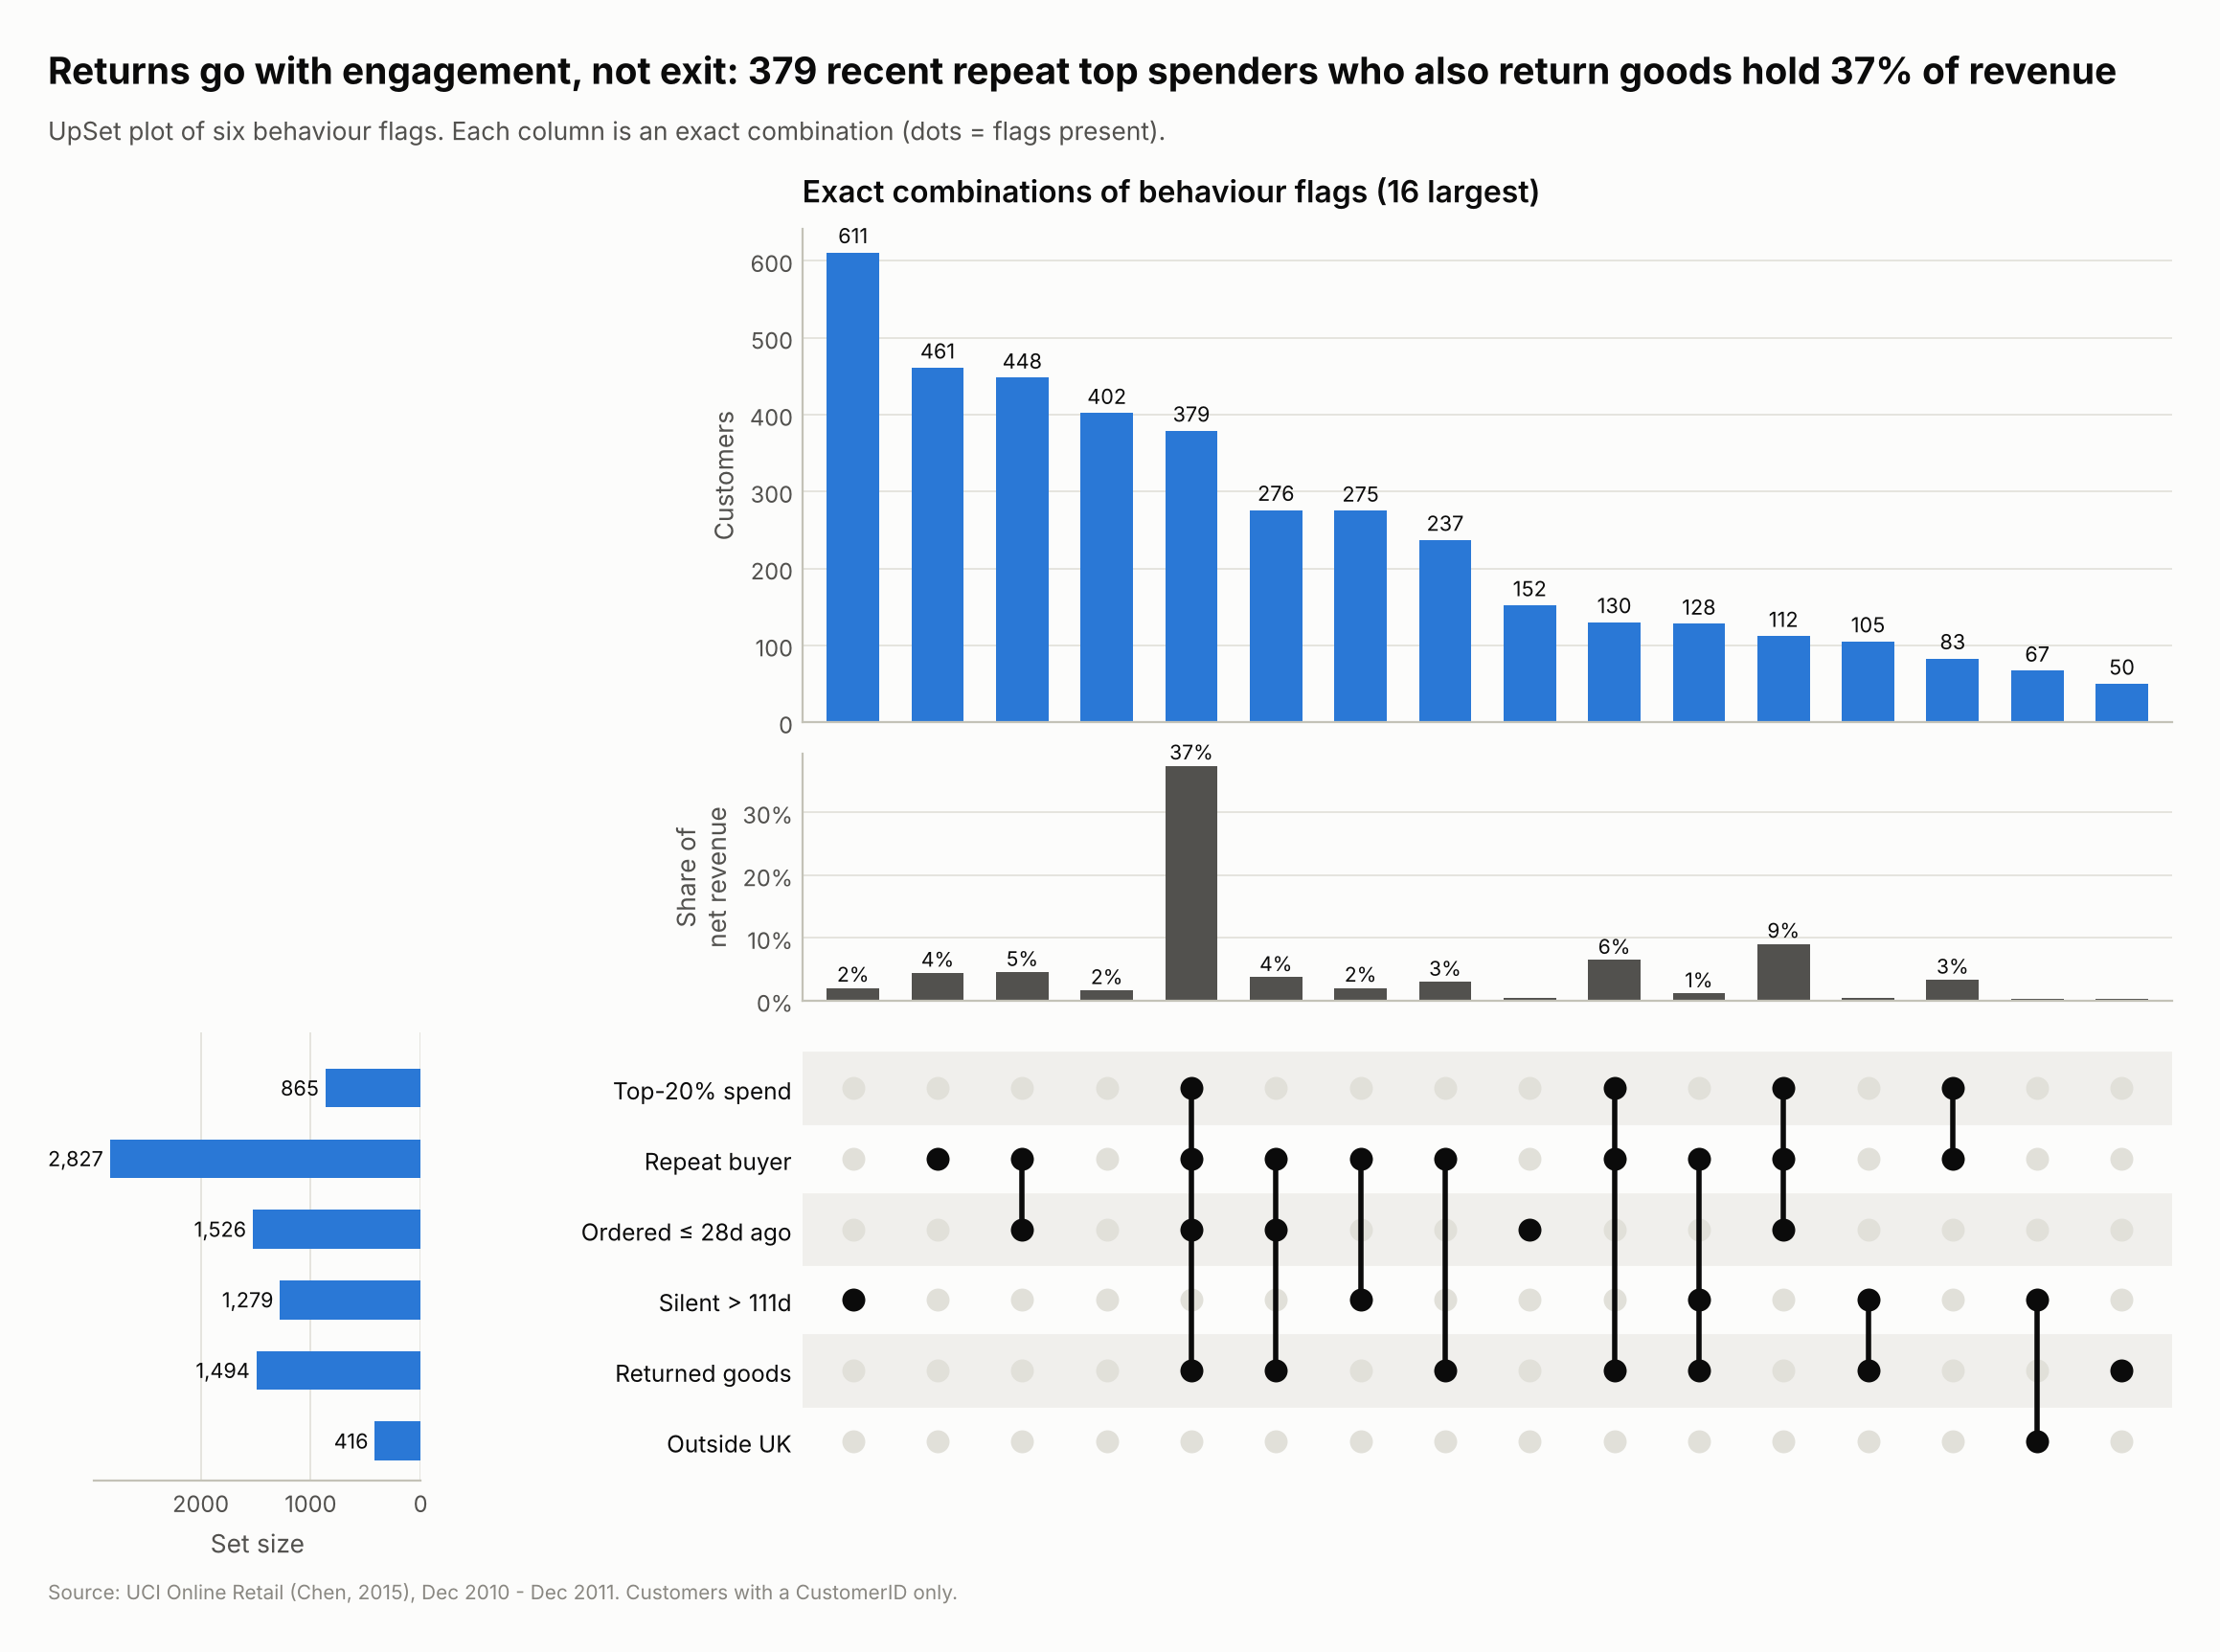

In [19]:
show(charts.fig_upset(res.customers, m['median_gap_days'], m['p90_gap_days']), "10_behaviour_upset")

**解读**：最大的单一群体是"只买过一次、已沉寂、英国、无退货"的客户（611 人），收入贡献很小；
而"消费前 20% + 复购 + 近期活跃 + 有退货"的 379 人贡献了约 37% 的收入。**退货与高参与度同时出现**——
对批发客户来说退货是大额采购的副产品，把"有退货"当成负面信号去打分会误伤最好的客户。

## 9. 客户生命周期价值（CLV）

### 9.1 模型

- **BG/NBD**（Fader, Hardie & Lee 2005）：购买频率服从 Gamma 异质的泊松过程，每次购买后以 Beta 异质的概率"死亡"，预测未来 t 天的期望购买天数。
- **Gamma-Gamma**：预测每次购买的期望金额（只用有复购的客户拟合）。
- CLV(180 天) = 期望购买天数 × 期望单次金额（未折现、毛收入口径）。

两个模型都按论文的闭式似然自行实现（`src/rfm/clv.py`），单元测试用**已知参数的模拟数据**验证能把参数估回来。
"交易"定义为"有净购买的客户-日"：同一天下单又全部取消的日子不算交易（否则客户 16446 那笔 £168k 的即退订单会给他一个六位数 CLV）。

### 9.2 先验证，再使用

用 2010-12-01 至 2011-09-09 拟合，预测接下来 13 周（2011-09-10 至 12-09），与真实值比较，并与两个透明基线对比：**复购速率基线** = 复购天数 ÷ 在网天数 × 91（公平基线）；**run-rate 基线** = (复购天数 + 1) ÷ 在网天数 × 91（把首单也算进去，会系统性高估）。

In [20]:
pd.DataFrame({
    name: {"预测总量": m[f"holdout_{name}_total"], "MAE": m[f"holdout_{name}_mae"], "Spearman": m[f"holdout_{name}_spearman"]}
    for name in ("bgnbd", "repeat_rate", "run_rate")
}).T.assign(实际总量=m["holdout_actual_total"]).round(3)

,预测总量,MAE,Spearman,实际总量
bgnbd,"3,297.71",0.93,0.50,4428
repeat_rate,"3,119.77",0.91,0.50,4428
run_rate,"7,277.23",1.63,0.42,4428


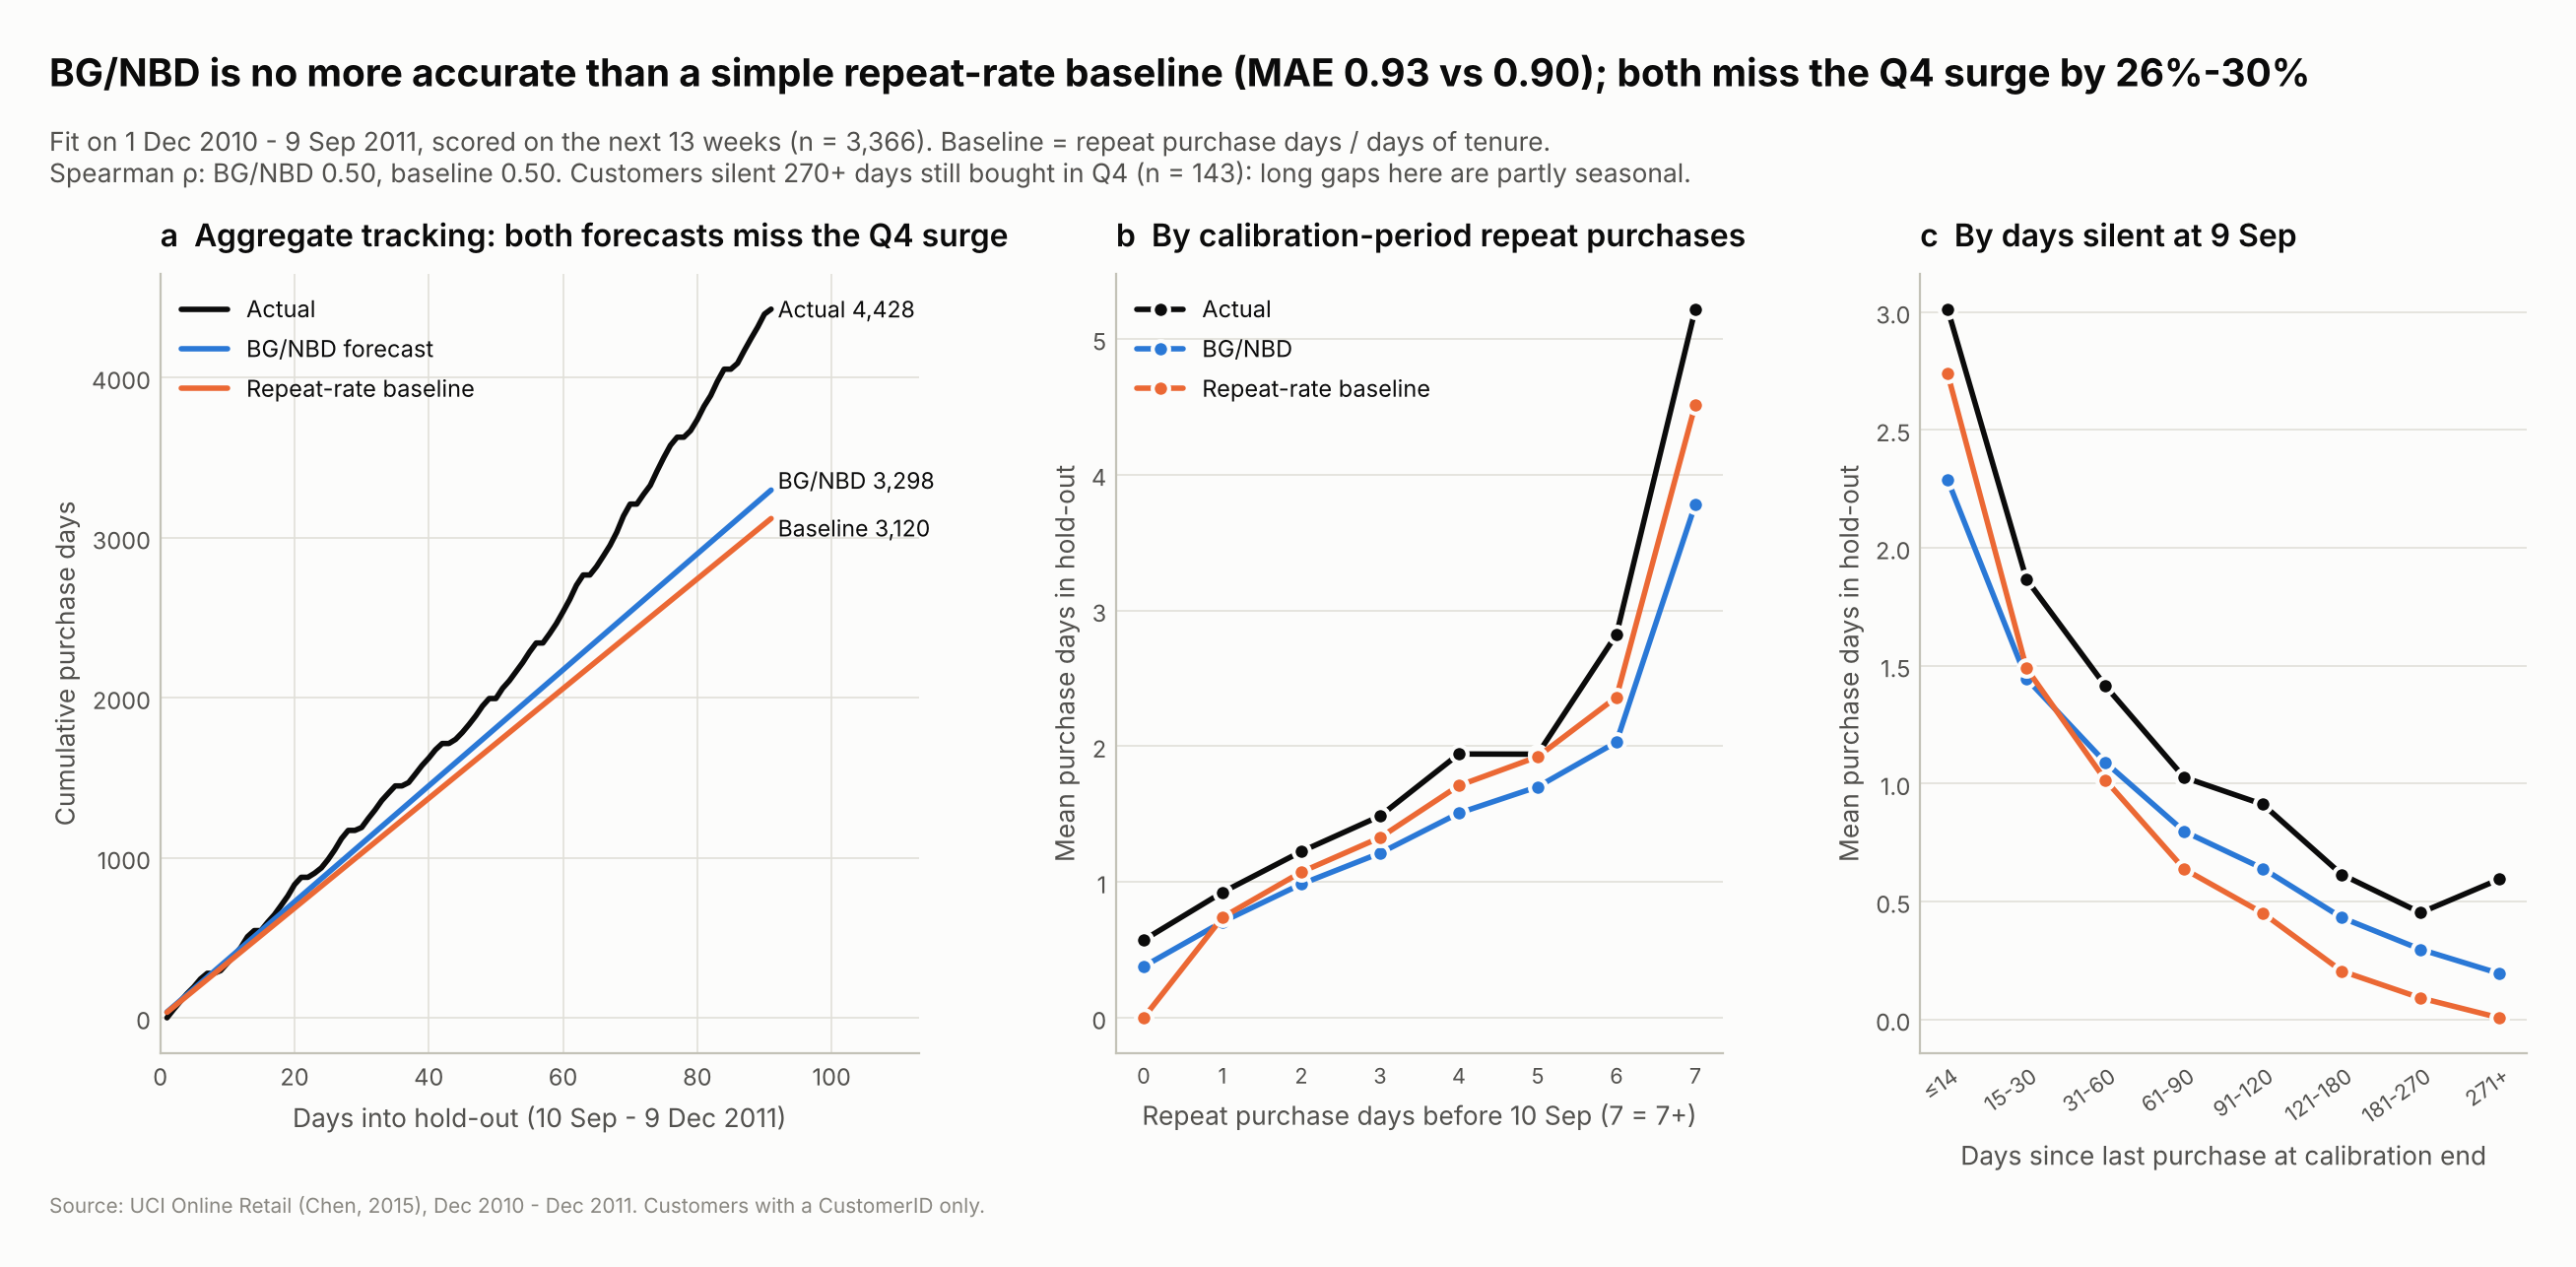

In [21]:
show(charts.fig_clv_validation(res.holdout, res.holdout_tracking, m), "13_clv_validation")

**批判性解读**：

1. **BG/NBD 并不比简单基线更准**：它与复购速率基线几乎持平（MAE 0.93 vs 0.90，Spearman 0.50 vs 0.50），只明显优于把首单也算进去的 run-rate 基线（MAE 1.63）。在这份数据上，概率模型没有带来额外的预测精度；它的价值在于有理论依据的外推（对只买过一次的客户也给出非零预期），以及可以与 Gamma-Gamma 组合成 CLV。如果只需要给客户排序，复购速率就够用。
2. **总量上都低估**：BG/NBD 低估约 26%，基线低估约 30%。留出期恰好是圣诞备货旺季，而两者都假设购买率平稳；图 a 中实际值在第 20 天后与预测分叉，正是季节性。
3. **模型认为几乎没人"死亡"**：全量拟合的平均流失概率 a/(a+b) ≈ 0，P(alive) > 0.95 的客户占 100%。这不是代码错误（模拟数据测试能正确识别流失），
   而是数据本身：图 c 显示，到 9 月已沉寂 270 天以上的客户在 Q4 仍平均下单 0.6 次、38% 至少下单一次（n = 143，样本偏小）——**长时间不下单在这家批发商很大程度上是季节性的，而不是流失**。
   所以本项目**不用 P(alive) 当流失标签**，而用复购间隔 P90 的经验阈值（第 6 节）。
4. Gamma-Gamma 要求"频率与金额独立"：复购客户中两者相关系数为 0.17，轻度违反，金额预测对高频客户略有偏差。

In [22]:
print("BG/NBD (全量):", {k: round(v, 4) for k, v in m['bgnbd_params'].items()})
print("Gamma-Gamma:  ", {k: round(v, 3) for k, v in m['gamma_gamma_params'].items()})
print(f"Gamma-Gamma 独立性检验 corr(x, m) = {m['gg_freq_spend_corr']:.2f}")
print(f"未来 180 天预测收入合计 £{m['clv_total_180d']:,.0f}")
res.customers.sort_values('clv', ascending=False)[['segment', 'frequency', 'monetary', 'exp_purchases', 'exp_spend', 'clv']].head(10)

BG/NBD (全量): {'r': 0.8218, 'alpha': 70.1747, 'a': 0.0031, 'b': 128.1421}
Gamma-Gamma:   {'p': 2.293, 'q': 3.495, 'gamma': 443.394}
Gamma-Gamma 独立性检验 corr(x, m) = 0.17
未来 180 天预测收入合计 £4,319,171


,segment,frequency,monetary,exp_purchases,exp_spend,clv
CustomerID,,,,,,
14646,Champions,72,"278,778.02",18.97,"6,199.54","117,617.38"
18102,Champions,60,"259,657.30",10.61,"8,976.52","95,205.78"
17450,Champions,46,"189,575.53",11.02,"7,116.53","78,400.33"
14096,Champions,17,"53,258.43",17.58,"3,142.02","55,244.15"
14911,Champions,198,"128,768.24",52.19,"1,008.77","52,645.44"
12415,Champions,20,"123,638.18",6.09,"8,340.03","50,828.26"
14156,Champions,54,"113,685.77",17.43,"2,704.60","47,136.63"
17511,Champions,31,"88,138.20",11.27,"3,093.52","34,873.58"
16684,Champions,28,"65,920.12",6.22,"4,388.11","27,275.62"


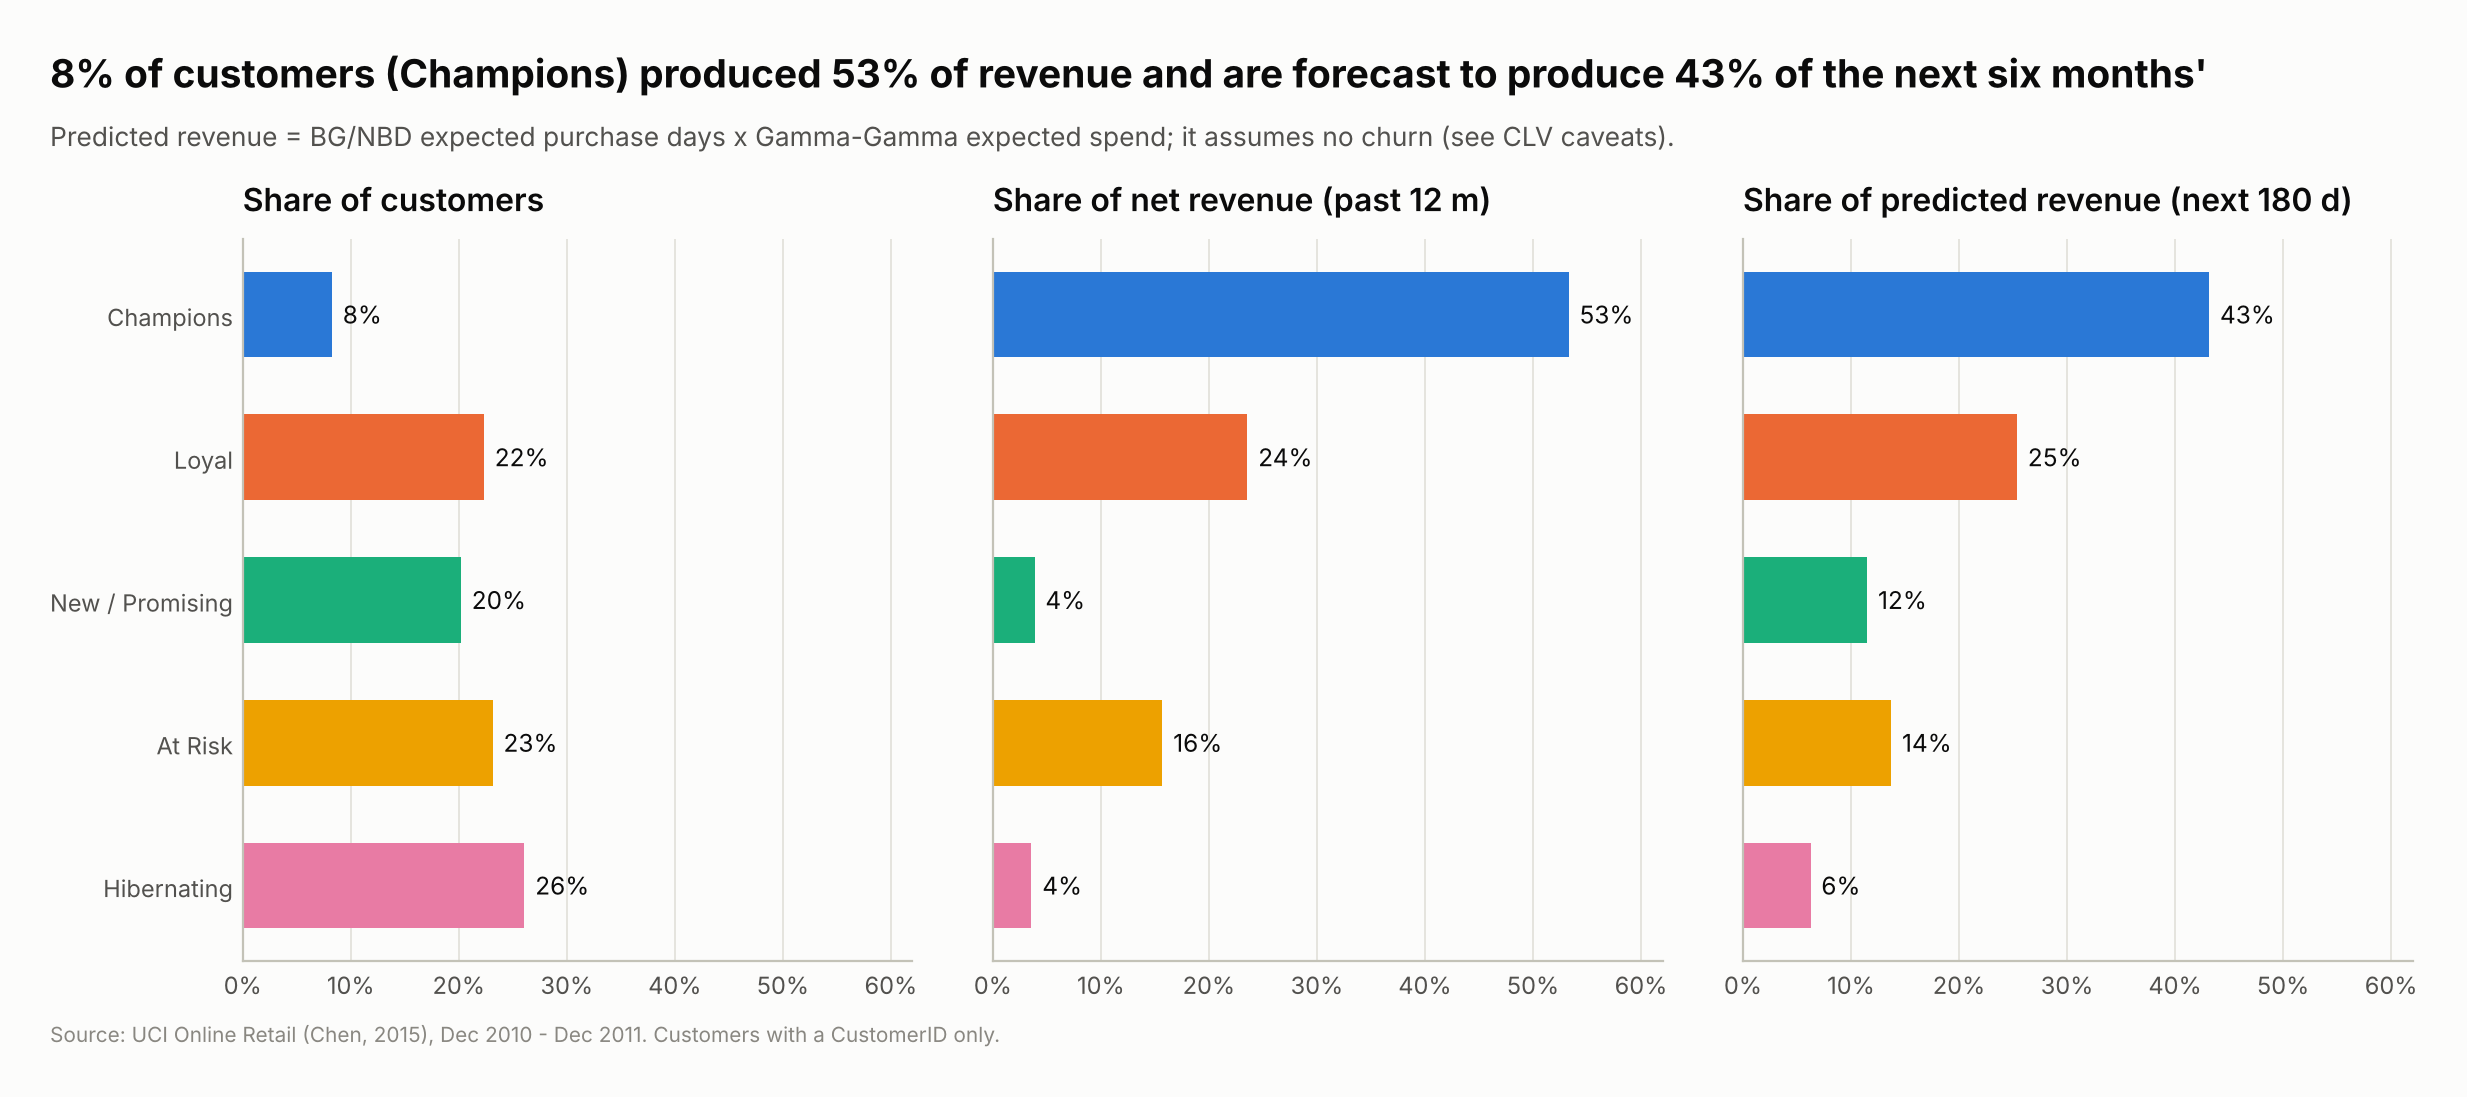

,Share of customers,Share of net revenue (past 12 m),Share of predicted revenue (next 180 d)
segment,,,
Champions,0.08,0.53,0.43
Loyal,0.22,0.24,0.25
New / Promising,0.20,0.04,0.12
At Risk,0.23,0.16,0.14
Hibernating,0.26,0.04,0.06


In [23]:
fig, shares = charts.fig_segment_value(res.customers)
show(fig, "12_segment_value_shares")
shares.round(3)

### 9.3 生命周期流向（桑基 / 冲积图）

获客时期 → 价值分群 → 预测 CLV 档位。带宽 = 客户数，颜色 = 分群。

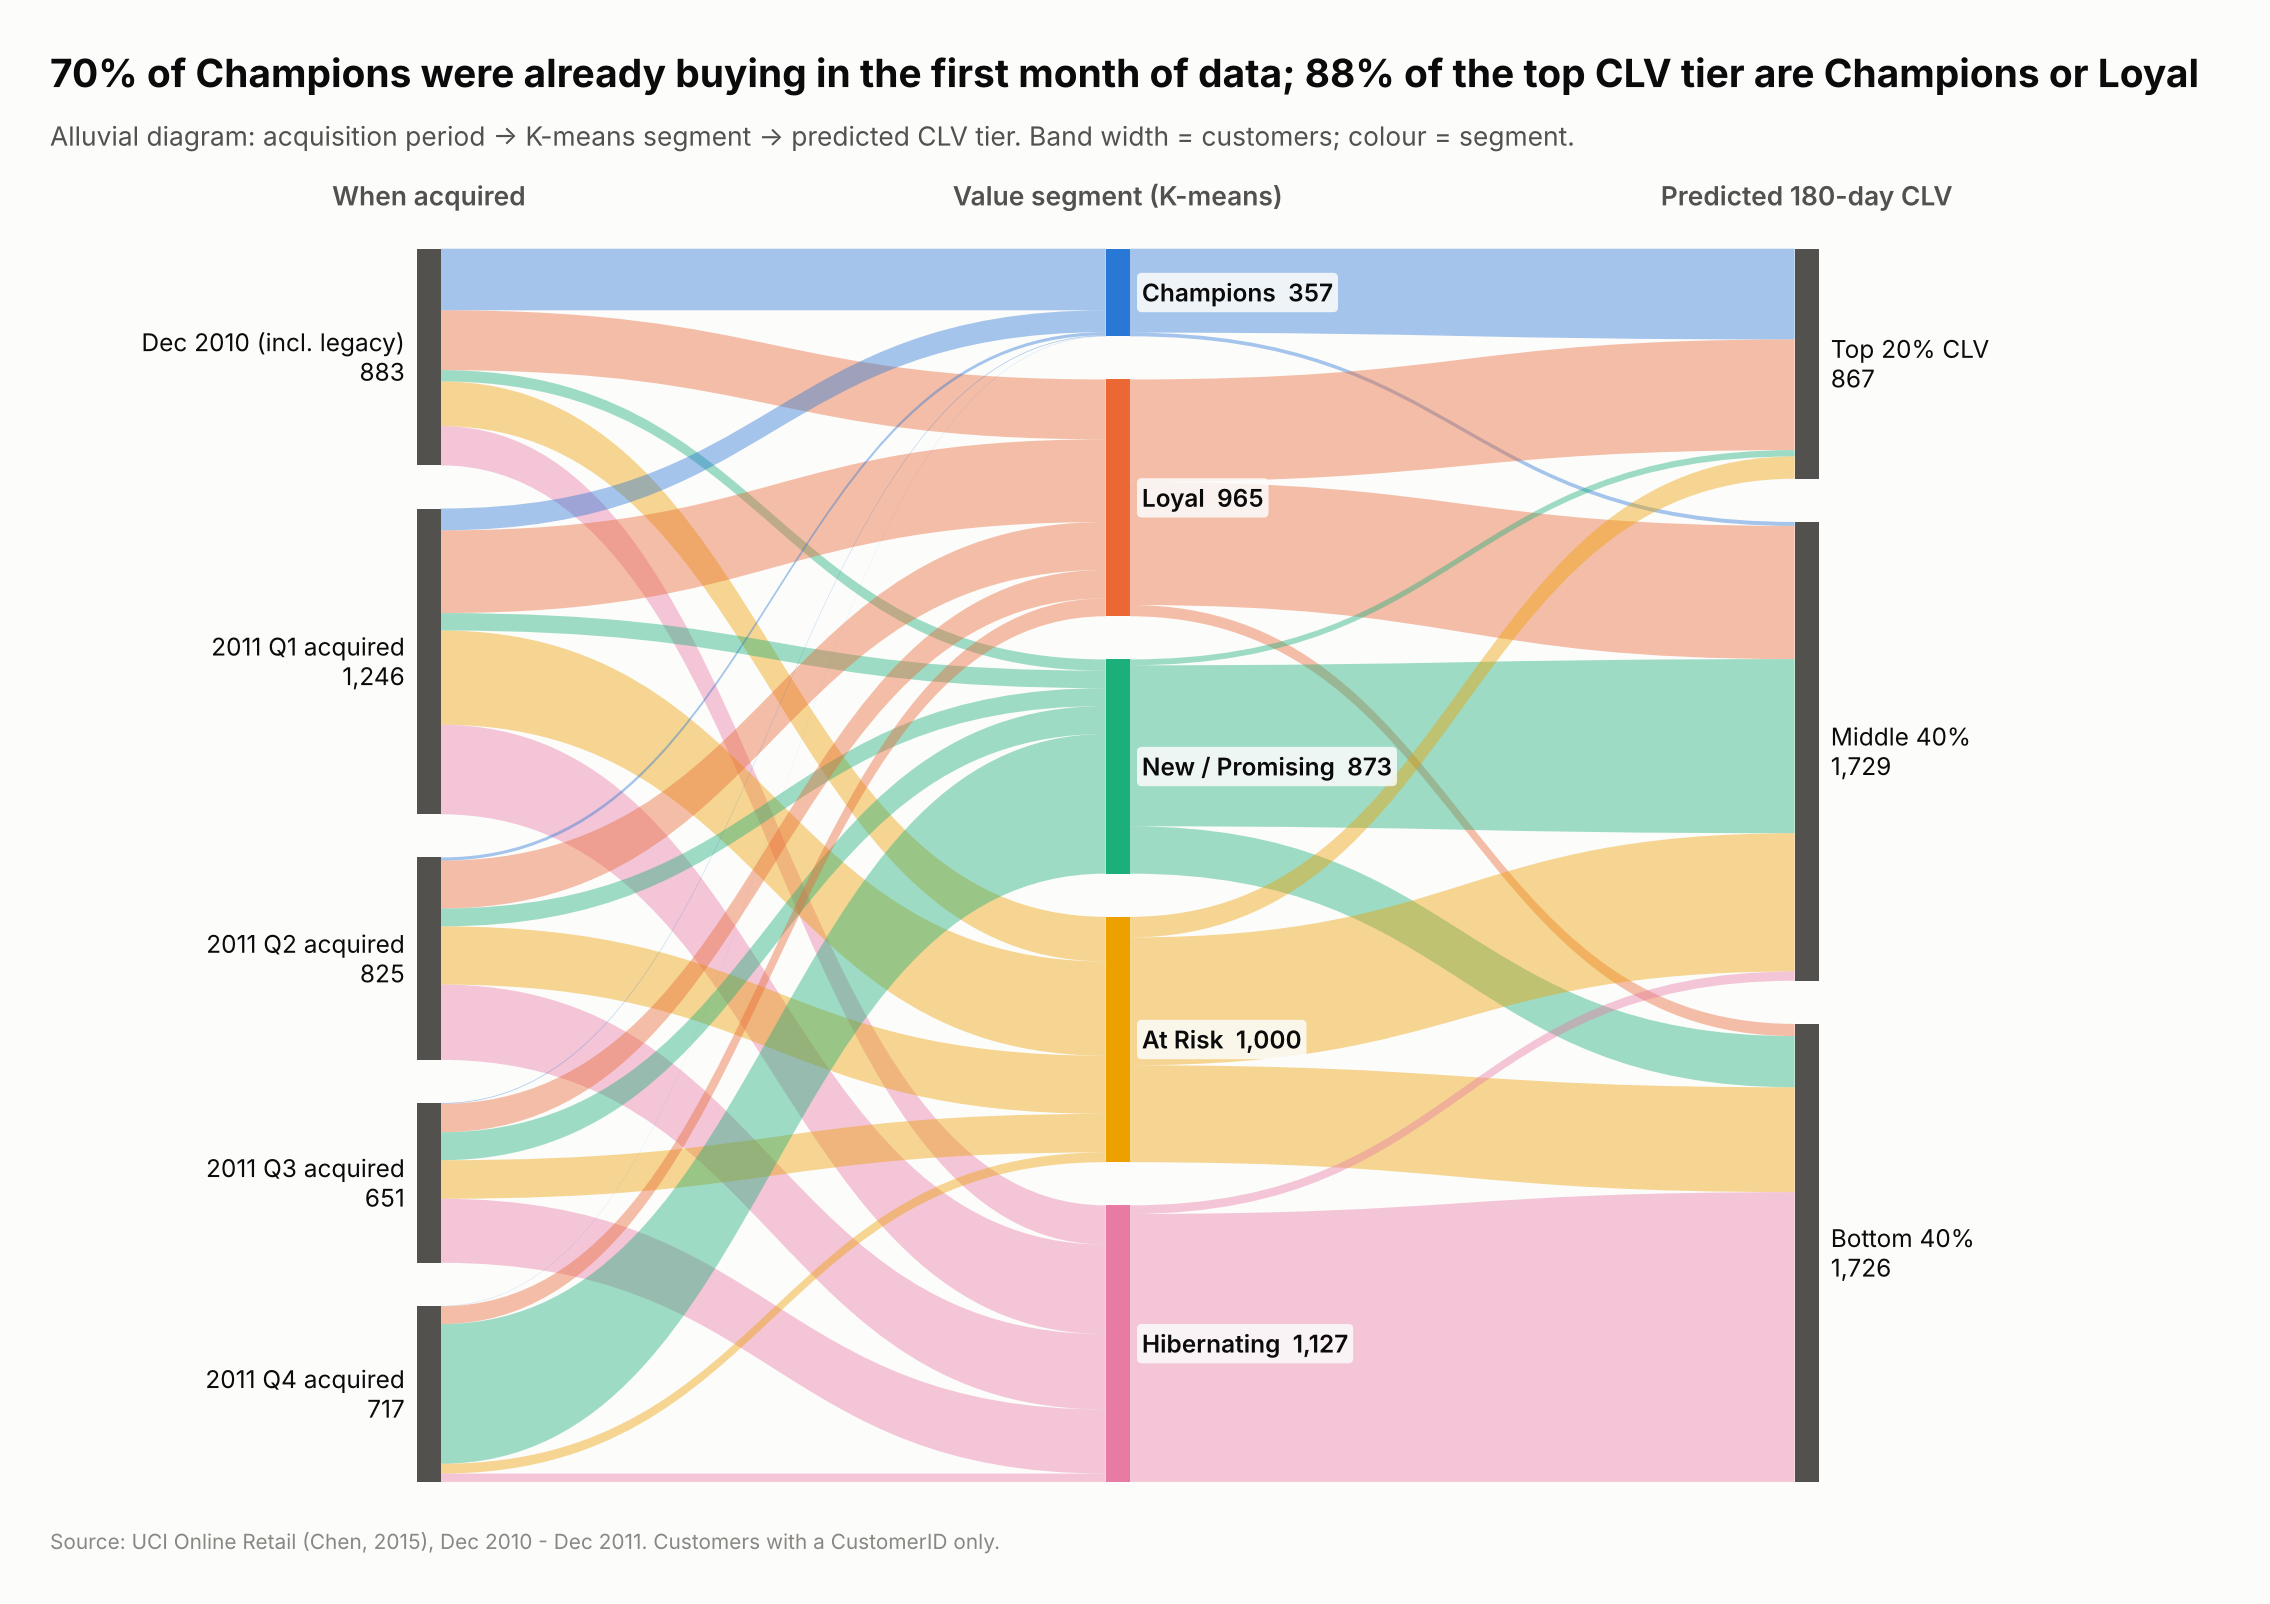

In [24]:
show(charts.fig_lifecycle_sankey(res.customers), "14_lifecycle_sankey")

**解读**：70% 的 Champions 在数据的第一个月（2010-12）就已经在下单。其中大部分很可能是早已存在的老客户（左删失），但无法与当月真正的新客区分。2011 年新获客中只有很少一部分在一年内成长为 Champions；
Top 20% CLV 档几乎全部来自 Champions 和 Loyal。增长杠杆因此在**把 Loyal 推成 Champions、把 At Risk 拉回来**，而不是单纯拉新。

## 10. 业务建议（按分群）

| 分群 | 人数 | 收入占比 | 画像（中位数） | 建议动作 |
|---|---|---|---|---|
| Champions | 357 | 53% | 8 天前下单，15 单，£5.7k | 专属客户经理、提前锁定 Q4 备货、新品优先试用；监控是否超过个人复购间隔 |
| Loyal | 965 | 24% | 17 天前，5 单，£1.7k | 交叉销售与阶梯返利，目标是提频到 Champions |
| New / Promising | 873 | 4% | 26 天前，1 单，£333 | 首单后 2–4 周（中位复购间隔 28 天）内触达，推动第二单 |
| At Risk | 1,000 | 16% | 84 天前，3 单，£964 | **挽留优先级最高**：曾有约 60 天的复购节奏，已超期；在 Q4 前做召回 |
| Hibernating | 1,127 | 4% | 219 天前，1 单，£233 | 低成本批量触达（季节性召回邮件），不投入一对一资源 |

## 11. 局限

- 只覆盖有 CustomerID 的交易（约 85% 收入）；游客结账的行为无法分析。
- 13 个月的数据只包含一个旺季：季节性无法与趋势分离，CLV 只能做 180 天的短期预测，且未折现、无毛利率数据（收入口径而非利润口径）。
- 90% 的客户在英国，海外客户的结论样本量小。
- 分群是对连续体的切分（Silhouette ≈ 0.32），边界附近的客户分类不稳定；业务使用时建议配合代理决策树的规则。
- BG/NBD 的"无流失"结论依赖于 13 个月的观察窗；更长的数据可能识别出真实的流失过程。